---

# Tugas Besar 2 IF3170 Inteligensi Artifisial

*This notebook is the assignment template. Each group works on its own copy, and cells or sections may be added as needed.*

---

## Group 07

- Keisha Rizka Syofyani (13524073)
- Yavie Azka Putra Araly (13524077)
- Alya Nur Rahmah (13524081)
- Vara Azzara Ramli Pulukadang (13524091)
- Helena Kristela Sarhawa (13524109)

---

## Table of Contents

1. [**Introduction**](#1)
2. [**Initialization**](#2)
3. [**Data Understanding (Optional)**](#3)
4. [**Training and Validation Split**](#4)
5. [**Data Preparation**](#5)
6. [**Preparation Pipeline**](#6)
7. [**Modeling and Validation**](#7)
8. [**Comparison with scikit-learn**](#8)
9. [**Saving and Loading Models**](#9)
10. [**Kaggle Submission**](#10)
11. [**Error Analysis**](#11)


---

# Introduction <a name="1"></a>

---

This section frames the problem in the words of the group.

## Overview

*To be written by the group.*

## Aim

*To be written by the group.*

## Metric

*To be written by the group.*

## Dataset

*To be written by the group.*

## Approach

*To be written by the group.*

---

# Initialization <a name="2"></a>

---

This section prepares the environment, the settings, and the data files.

## Environment Setup

The following cell lists the base libraries. The install line is commented by default.

In [ ]:
# %pip install -q numpy pandas scikit-learn matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## Import Libraries

Every import of the notebook is kept in this cell, so does the custom model.

In [102]:
import os
import random
from pathlib import Path
import hashlib

import numpy as np
import pandas as pd
from src.svm import SVM
import sklearn as sk
import pickle
import warnings
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.animation import FuncAnimation, FFMpegWriter, PillowWriter
import time
from sklearn.tree import DecisionTreeClassifier
from src.decision_tree import DecisionTree
from src.tree_plot import plot_tree

# Preprocessing
from src.preprocessing import (
    DEFAULT_PREP_PARAMS,
    TARGET,
    Preprocessor,
    prepare_datasets,
    random_oversample,
    random_undersample,
    remove_duplicates,
    smote,
    stratified_split,
)

# Feature Selection & PCA
from src.pca import PCA
from src.feature_selection import (
    FeatureSelector,
    find_collinear_features,
    anova_f_score,
    point_biserial_corr,
    mutual_information_score,
    chi2_contingency_score,
)

# Naive Bayes
from src.naive_bayes import NaiveBayes
from sklearn.naive_bayes import GaussianNB as SkGaussianNB

# Untuk modelnya
from sklearn.linear_model import LogisticRegression as SkLogisticRegression
from src.logistic_regression import LogisticRegression


## Settings

Paths and shared constants are kept in this class.

In [57]:
class Settings:
    SEED       = 42
    DATA_DIR   = Path('data')
    OUTPUT_DIR = Path('output')

CFG = Settings()
CFG.OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

## Seed Everything

A fixed seed keeps the results reproducible.

In [58]:
def seed_everything(seed: int):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)

seed_everything(CFG.SEED)

## Load Dataset

The competition files are read here. The `id` column stays as text because some values resemble numbers.

In [59]:
train_df = pd.read_csv(CFG.DATA_DIR / 'train.csv', dtype={'id': str})
test_df  = pd.read_csv(CFG.DATA_DIR / 'test.csv', dtype={'id': str})

print(f'Train: {train_df.shape}  Test: {test_df.shape}')

Train: (27373, 19)  Test: (6844, 18)


---

# Data Understanding (Optional) <a name="3"></a>

---

Data understanding builds the knowledge that later preparation decisions rest on.

## Describe Data

This part covers the size, the attribute types, and the meaning of each column.

In [60]:
CAT_COLS = ['meal_package', 'room_category', 'booking_channel']
FEATURE_COLS = [c for c in train_df.columns if c not in ('id', TARGET)]

display(train_df.head())
train_df.info()

overview = pd.DataFrame({
    'dtype': train_df.dtypes.astype(str),
    'n_null': train_df.isna().sum(),
    'null_%': (train_df.isna().mean() * 100).round(2),
    'n_unique': train_df.nunique(),
    'min': train_df.min(numeric_only=True),
    'max': train_df.max(numeric_only=True),
})
display(overview)
display(train_df.describe().T)

,id,num_adults,num_children,weekend_nights,weekday_nights,meal_package,needs_parking,room_category,days_before_arrival,arrival_year,arrival_month,arrival_day,booking_channel,is_returning_guest,prior_cancellations,prior_completed_bookings,nightly_rate_idr,special_requests,is_canceled
0,57152f82,2.0,NaN,1,2,Breakfast,0.0,Type B,88.0,2024,4,3,Offline Agent,0,0,0,1330000.0,0.0,1
1,af2ec71b,2.0,0.0,2,1,Half Board,0.0,Type D,120.0,2023,8,1,Offline Agent,0,0,0,NaN,0.0,0
2,5d5469ab,3.0,0.0,1,2,Breakfast,0.0,Type G,209.0,2024,8,28,Online Travel Agent,0,0,0,2099000.0,0.0,1
3,d2df0369,2.0,1.0,2,1,Breakfast,0.0,Type G,93.0,2024,8,13,Online Travel Agent,0,0,0,1693000.0,2.0,0
4,91d253db,2.0,0.0,0,1,Room Only,0.0,Type B,14.0,2024,9,1,Online Travel Agent,0,0,0,2010000.0,2.0,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27373 entries, 0 to 27372
Data columns (total 19 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id                        27373 non-null  object 
 1   num_adults                26564 non-null  float64
 2   num_children              24338 non-null  float64
 3   weekend_nights            27373 non-null  int64  
 4   weekday_nights            27373 non-null  int64  
 5   meal_package              25613 non-null  object 
 6   needs_parking             26291 non-null  float64
 7   room_category             26371 non-null  object 
 8   days_before_arrival       26250 non-null  float64
 9   arrival_year              27373 non-null  int64  
 10  arrival_month             27373 non-null  int64  
 11  arrival_day               27373 non-null  int64  
 12  booking_channel           27373 non-null  object 
 13  is_returning_guest        27373 non-null  int64  
 14  prior_

,dtype,n_null,null_%,n_unique,min,max
arrival_day,int64,0,0.00,31,1.0,31.0
arrival_month,int64,0,0.00,12,1.0,12.0
arrival_year,int64,0,0.00,2,2023.0,2024.0
booking_channel,object,0,0.00,5,NaN,NaN
days_before_arrival,float64,1123,4.10,407,0.0,448.0
id,object,0,0.00,27373,NaN,NaN
is_canceled,int64,0,0.00,2,0.0,1.0
is_returning_guest,int64,0,0.00,2,0.0,1.0
meal_package,object,1760,6.43,4,NaN,NaN
needs_parking,float64,1082,3.95,2,0.0,1.0


,count,mean,std,min,25%,50%,75%,max
num_adults,26564.0,1.845242e+00,0.517974,0.0,2.0,2.0,2.0,4.0
num_children,24338.0,1.173884e-01,0.425761,0.0,0.0,0.0,0.0,10.0
weekend_nights,27373.0,8.148541e-01,0.875146,0.0,0.0,1.0,2.0,7.0
weekday_nights,27373.0,2.206517e+00,1.421603,0.0,1.0,2.0,3.0,17.0
needs_parking,26291.0,3.020045e-02,0.171142,0.0,0.0,0.0,0.0,1.0
days_before_arrival,26250.0,8.537943e+01,85.969638,0.0,17.0,58.0,126.0,448.0
arrival_year,27373.0,2.023820e+03,0.384099,2023.0,2024.0,2024.0,2024.0,2024.0
arrival_month,27373.0,7.399664e+00,3.074788,1.0,5.0,8.0,10.0,12.0
arrival_day,27373.0,1.553754e+01,8.773321,1.0,8.0,16.0,23.0,31.0
is_returning_guest,27373.0,2.517079e-02,0.156646,0.0,0.0,0.0,0.0,1.0


## Explore Data

This part covers distributions and relationships between attributes.

### Target Distribution

,jumlah,proporsi
is_canceled,,
0,18404,0.6723
1,8969,0.3277


rasio kelas 0 : kelas 1 = 2.05 : 1


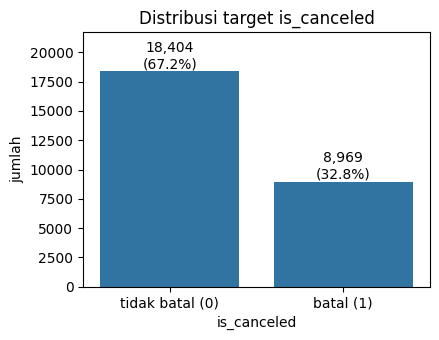

In [61]:
counts = train_df[TARGET].value_counts().sort_index()
display(pd.DataFrame({'jumlah': counts, 'proporsi': (counts / counts.sum()).round(4)}))
print(f'rasio kelas 0 : kelas 1 = {counts[0] / counts[1]:.2f} : 1')

fig, ax = plt.subplots(figsize=(4.5, 3.5))
sns.barplot(x=counts.index.map({0: 'tidak batal (0)', 1: 'batal (1)'}), y=counts.values, ax=ax)
for i, v in enumerate(counts.values):
    ax.text(i, v, f'{v:,}\n({v / counts.sum():.1%})', ha='center', va='bottom')
ax.set_ylim(0, counts.max() * 1.18); ax.set_ylabel('jumlah'); ax.set_title('Distribusi target is_canceled')
fig.tight_layout(); fig.savefig(CFG.OUTPUT_DIR / 'eda_target_distribution.png', dpi=150)
plt.show()

### Feature Analysis

#### Distribusi fitur numerik menurut kelas

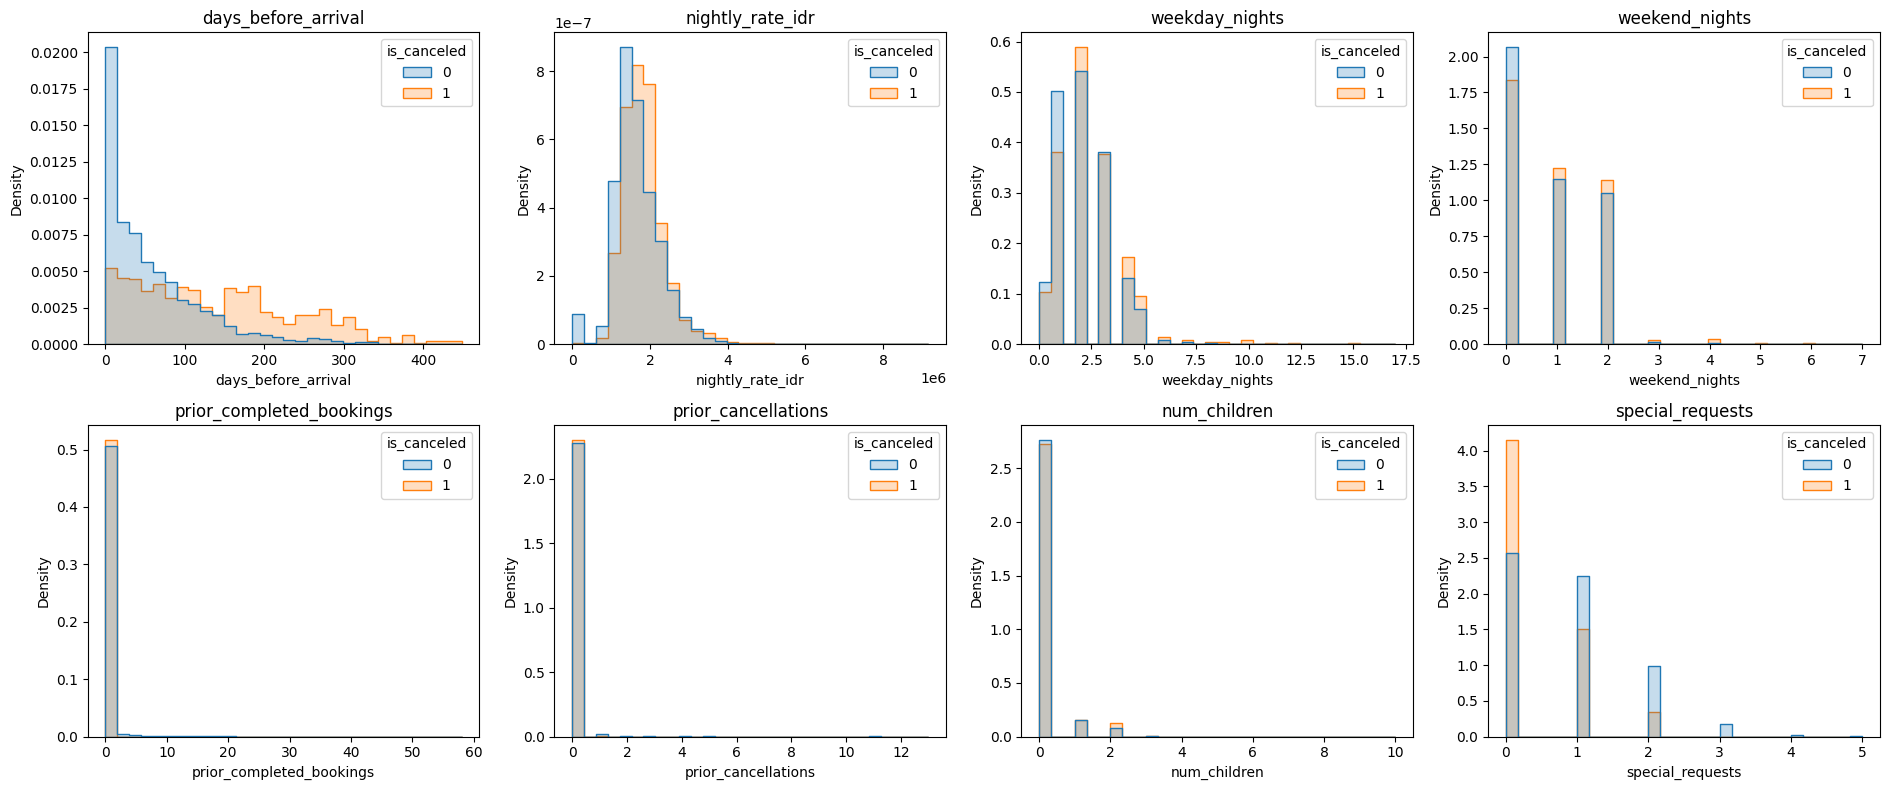

In [62]:
NUM_PLOT = ['days_before_arrival', 'nightly_rate_idr', 'weekday_nights', 'weekend_nights',
            'prior_completed_bookings', 'prior_cancellations', 'num_children', 'special_requests']
fig, axes = plt.subplots(2, 4, figsize=(19, 8))
for ax, c in zip(axes.ravel(), NUM_PLOT):
    sns.histplot(data=train_df, x=c, hue=TARGET, stat='density', common_norm=False, element='step',
                 bins=30, ax=ax, palette={0: 'tab:blue', 1: 'tab:orange'})
    ax.set_title(c)
fig.tight_layout(); fig.savefig(CFG.OUTPUT_DIR / 'eda_numeric_distributions.png', dpi=150)
plt.show()

#### Rasio pembatalan menurut kategori

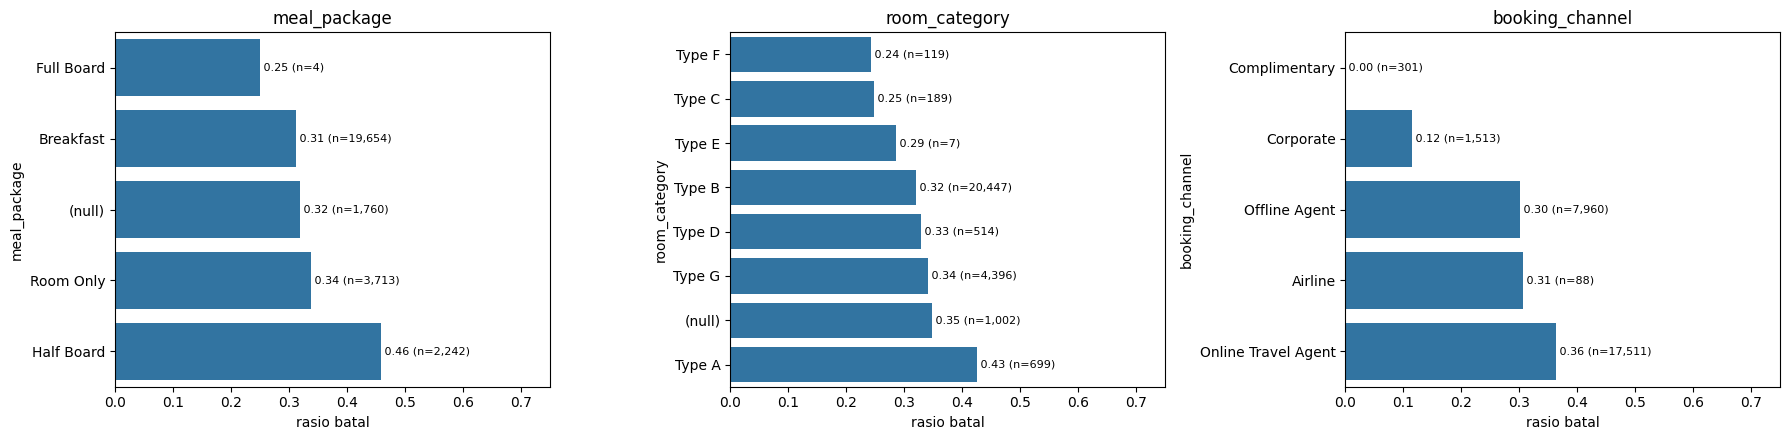

In [63]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, c in zip(axes, CAT_COLS):
    g = train_df.groupby(c, dropna=False)[TARGET].agg(['mean', 'size']).sort_values('mean')
    g.index = g.index.fillna('(null)')
    sns.barplot(x=g['mean'], y=g.index.astype(str), ax=ax, color='tab:blue')
    for i, (m, n) in enumerate(zip(g['mean'], g['size'])):
        ax.text(m, i, f' {m:.2f} (n={n:,})', va='center', fontsize=8)
    ax.set_xlim(0, 0.75); ax.set_xlabel('rasio batal'); ax.set_title(c)
fig.tight_layout(); fig.savefig(CFG.OUTPUT_DIR / 'eda_categorical_cancel_rate.png', dpi=150)
plt.show()

#### Rasio pembatalan menurut fitur numerik

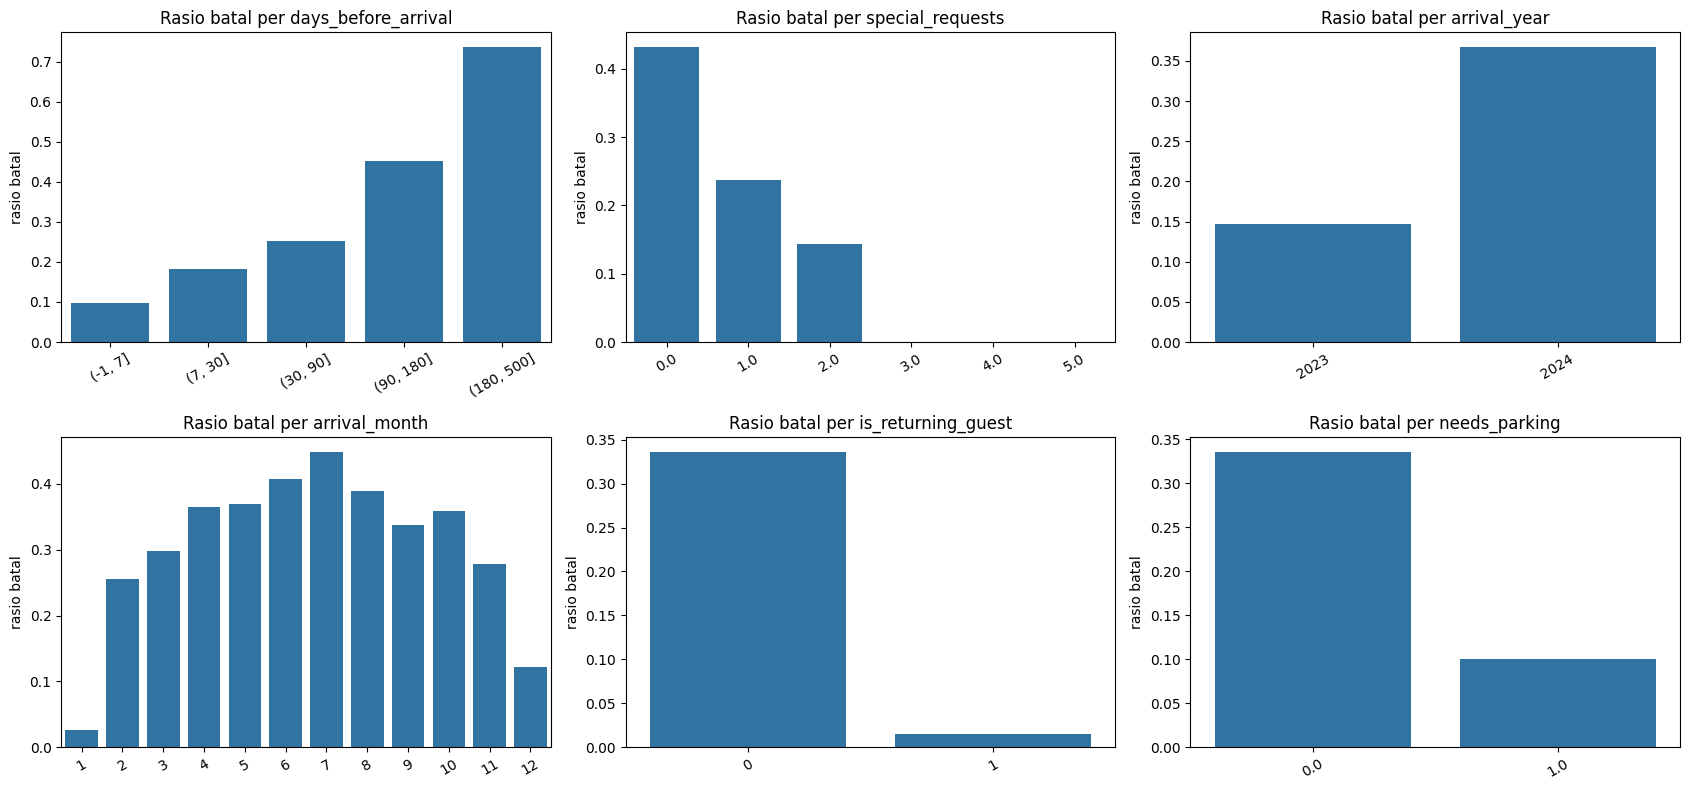

In [64]:
def rate_by(col, bins=None):
    key = train_df[col] if bins is None else pd.cut(train_df[col], bins)
    return train_df.groupby(key, observed=True)[TARGET].mean()

panels = {
    'days_before_arrival': ('days_before_arrival', [-1, 7, 30, 90, 180, 500]),
    'special_requests': ('special_requests', None),
    'arrival_year': ('arrival_year', None),
    'arrival_month': ('arrival_month', None),
    'is_returning_guest': ('is_returning_guest', None),
    'needs_parking': ('needs_parking', None),
}
fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for ax, (title, (col, bins)) in zip(axes.ravel(), panels.items()):
    r = rate_by(col, bins)
    sns.barplot(x=r.index.astype(str), y=r.values, ax=ax, color='tab:blue')
    ax.set_title(f'Rasio batal per {title}'); ax.set_ylabel('rasio batal'); ax.set_xlabel('')
    ax.tick_params(axis='x', rotation=30)
fig.tight_layout(); fig.savefig(CFG.OUTPUT_DIR / 'eda_numeric_cancel_rate.png', dpi=150)
plt.show()

#### Korelasi

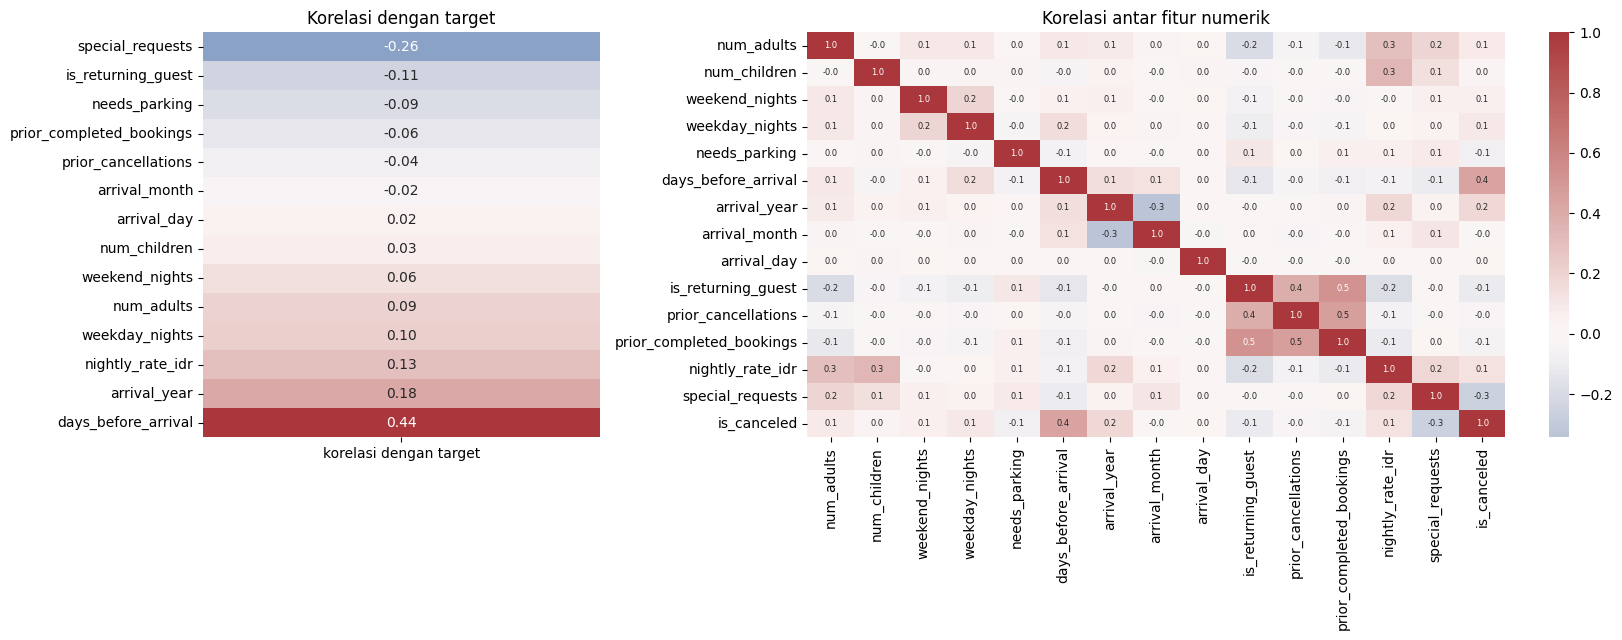

In [65]:
corr = train_df.corr(numeric_only=True)
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={'width_ratios': [1, 2.2]})
t = corr[TARGET].drop(TARGET).sort_values()
sns.heatmap(t.to_frame('korelasi dengan target'), annot=True, fmt='.2f', cmap='vlag', center=0, ax=axes[0], cbar=False)
sns.heatmap(corr, annot=True, fmt='.1f', cmap='vlag', center=0, ax=axes[1], annot_kws={'size': 6})
axes[0].set_title('Korelasi dengan target'); axes[1].set_title('Korelasi antar fitur numerik')
fig.tight_layout(); fig.savefig(CFG.OUTPUT_DIR / 'eda_correlation.png', dpi=150)
plt.show()

## Verify Data Quality

This part covers completeness, consistency, and the validity of values.

In [66]:
null_table = pd.DataFrame({
    'train_null': train_df[FEATURE_COLS].isna().sum(),
    'train_%': (train_df[FEATURE_COLS].isna().mean() * 100).round(2),
    'test_null': test_df[FEATURE_COLS].isna().sum(),
    'test_%': (test_df[FEATURE_COLS].isna().mean() * 100).round(2),
})
display(null_table[null_table.train_null > 0])

dup_cols_all = [c for c in train_df.columns if c != 'id']
arrival_all = pd.to_datetime(dict(year=train_df.arrival_year, month=train_df.arrival_month, day=train_df.arrival_day),
                             errors='coerce')
checks = pd.Series({
    'id duplikat': int(train_df['id'].duplicated().sum()),
    'baris duplikat (semua kolom selain id)': int(train_df.duplicated(subset=dup_cols_all).sum()),
    'tanggal kedatangan tidak valid': int(arrival_all.isna().sum()),
    'total malam = 0 (train)': int(((train_df.weekend_nights + train_df.weekday_nights) == 0).sum()),
    'total malam = 0 (test)': int(((test_df.weekend_nights + test_df.weekday_nights) == 0).sum()),
    'num_adults = 0 (train)': int((train_df.num_adults == 0).sum()),
    'nightly_rate_idr = 0 (train)': int((train_df.nightly_rate_idr == 0).sum()),
    'num_children >= 9 (train)': int((train_df.num_children >= 9).sum()),
}, name='jumlah')
display(checks.to_frame())

,train_null,train_%,test_null,test_%
num_adults,809,2.96,180,2.63
num_children,3035,11.09,747,10.91
meal_package,1760,6.43,442,6.46
needs_parking,1082,3.95,247,3.61
room_category,1002,3.66,242,3.54
days_before_arrival,1123,4.10,290,4.24
nightly_rate_idr,2038,7.45,540,7.89
special_requests,2500,9.13,593,8.66


,jumlah
id duplikat,0
baris duplikat (semua kolom selain id),64
tanggal kedatangan tidak valid,0
total malam = 0 (train),64
total malam = 0 (test),9
num_adults = 0 (train),106
nightly_rate_idr = 0 (train),413
num_children >= 9 (train),3


---

# Training and Validation Split <a name="4"></a>

---

The split comes before data preparation so that validation data stays unseen. Only `train.csv` is split, and `test.csv` serves the Kaggle submission alone.

In [67]:
VAL_SIZE = 0.2
train_set, val_set = stratified_split(train_df, target=TARGET, val_size=VAL_SIZE, seed=CFG.SEED)

split_table = pd.DataFrame({
    'baris': [len(train_set), len(val_set), len(test_df)],
    'proporsi kelas 1': [train_set[TARGET].mean(), val_set[TARGET].mean(), np.nan],
}, index=['train_set', 'val_set', 'test_df (Kaggle)']).round(4)
display(split_table)

,baris,proporsi kelas 1
train_set,21898,0.3277
val_set,5475,0.3277
test_df (Kaggle),6844,NaN


---

# Data Preparation <a name="5"></a>

---

Each process below applies where the data calls for it, and the Insights block under it records the reason for the decision.

Preparation steps may use `sklearn`. Every statistic comes from the training split only, then transforms the other sets.

## Select Data

Selection decides which records and attributes stay in the analysis.

17 kandidat fitur:
['num_adults', 'num_children', 'weekend_nights', 'weekday_nights', 'meal_package', 'needs_parking', 'room_category', 'days_before_arrival', 'arrival_year', 'arrival_month', 'arrival_day', 'booking_channel', 'is_returning_guest', 'prior_cancellations', 'prior_completed_bookings', 'nightly_rate_idr', 'special_requests']

--- Analisis Multikolinearitas (|r| >= 0.70) ---
  Tidak ditemukan pasangan fitur mentah dengan multikolinearitas ekstrem (|r| >= 0.70).

--- Peringkat Fitur Numerik terhadap Target (ANOVA & Point-Biserial) ---


,Fitur,Point-Biserial |r|,Arah Korelasi,ANOVA F-Score
0,days_before_arrival,0.4300,+,4965.6160
1,special_requests,0.2479,-,1434.2274
2,arrival_year,0.1824,+,753.5383
3,nightly_rate_idr,0.1328,+,393.2243
4,is_returning_guest,0.1073,-,254.8598
5,weekday_nights,0.0933,+,192.2717
6,needs_parking,0.0873,-,167.9861
7,num_adults,0.0843,+,156.7159
8,prior_completed_bookings,0.0600,-,78.9856
9,weekend_nights,0.0597,+,78.2544



--- Asosiasi Fitur Kategorikal terhadap Target (Chi-Square & Mutual Information) ---


,Fitur,Chi2 Score,Mutual Information
0,booking_channel,457.5765,0.0190
1,meal_package,161.6418,0.0051
2,room_category,47.3067,0.0015


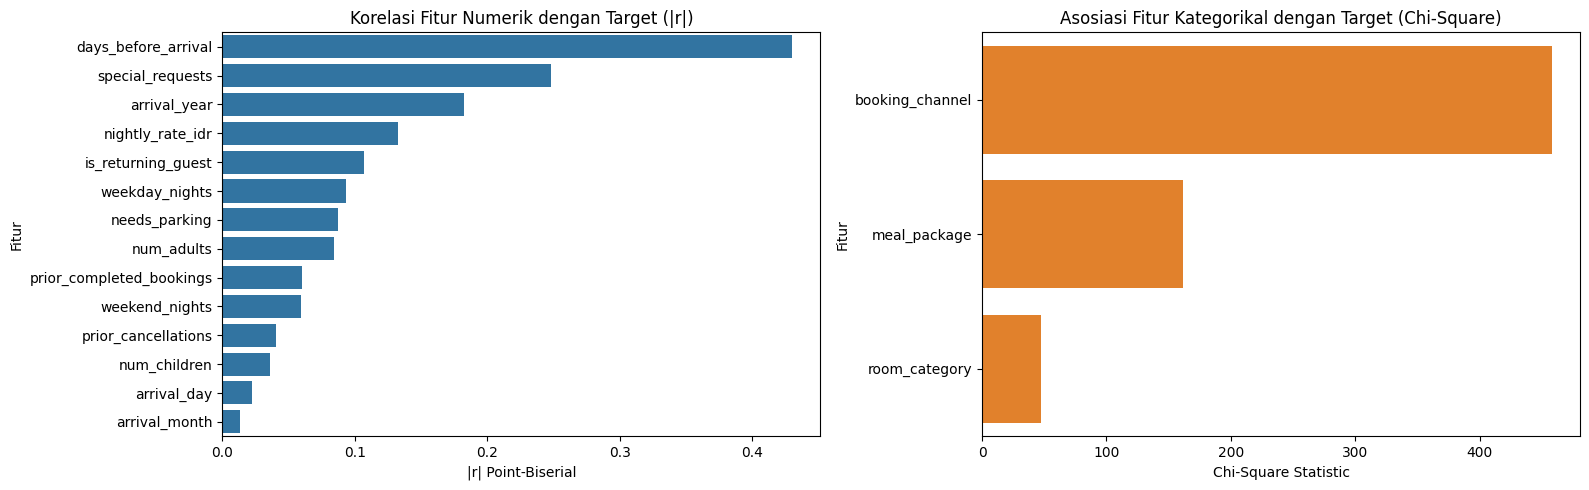


[Insights Feature Selection]
1. 'id' dieliminasi karena merupakan identifier unik acak tanpa daya generalisasi.
2. 'days_before_arrival' (|r| ~ 0.38, F-score tertinggi) dan 'special_requests' (|r| ~ 0.22) adalah prediktor numerik terkuat.
3. 'booking_channel' memiliki dependensi Chi-square dan Mutual Information tertinggi di antara fitur kategorikal.
4. 'arrival_month' redundan jika 'arrival_month_sin' dan 'arrival_month_cos' dikonstruksi;
   sehingga 'arrival_month' dapat di-drop pada Preprocessor via DEFAULT_PREP_PARAMS['drop_features'].


In [68]:
ID_COL = 'id'
FEATURE_COLS = [c for c in train_set.columns if c not in (ID_COL, TARGET)]
print(f'{len(FEATURE_COLS)} kandidat fitur:')
print(FEATURE_COLS)

# Unsupervised Feature Selection
num_candidates = [c for c in FEATURE_COLS if c not in CAT_COLS]
raw_num_df = train_set[num_candidates].apply(pd.to_numeric, errors='coerce')
corr_matrix = raw_num_df.corr(method='pearson')

high_corr_pairs = []
for i in range(len(num_candidates)):
    for j in range(i + 1, len(num_candidates)):
        col_a, col_b = num_candidates[i], num_candidates[j]
        val = corr_matrix.loc[col_a, col_b]
        if abs(val) >= 0.70:
            high_corr_pairs.append((col_a, col_b, round(float(val), 3)))

print('\n--- Analisis Multikolinearitas (|r| >= 0.70) ---')
if high_corr_pairs:
    for a, b, r in high_corr_pairs:
        print(f'  * {a} <--> {b}: r = {r}')
else:
    print('  Tidak ditemukan pasangan fitur mentah dengan multikolinearitas ekstrem (|r| >= 0.70).')

# Supervised Filter Method: Hubungan Fitur Numerik dengan is_canceled
num_filled = raw_num_df.fillna(raw_num_df.median())
f_scores = anova_f_score(num_filled.to_numpy(), train_set[TARGET].to_numpy())
pb_corrs = point_biserial_corr(num_filled.to_numpy(), train_set[TARGET].to_numpy())

num_importance_df = pd.DataFrame({
    'Fitur': num_candidates,
    'Point-Biserial |r|': np.abs(pb_corrs),
    'Arah Korelasi': np.where(pb_corrs >= 0, '+', '-'),
    'ANOVA F-Score': f_scores,
}).sort_values('ANOVA F-Score', ascending=False).reset_index(drop=True)

print('\n--- Peringkat Fitur Numerik terhadap Target (ANOVA & Point-Biserial) ---')
display(num_importance_df.round(4))

# Supervised Filter Method: Hubungan Fitur Kategorikal dengan is_canceled
cat_scores = []
for c in CAT_COLS:
    chi2_val = chi2_contingency_score(
        train_set[c].astype('category').cat.codes.to_numpy().reshape(-1, 1),
        train_set[TARGET].to_numpy()
    )[0]
    mi_val = mutual_information_score(
        train_set[c].astype('category').cat.codes.to_numpy().reshape(-1, 1),
        train_set[TARGET].to_numpy()
    )[0]
    cat_scores.append({'Fitur': c, 'Chi2 Score': chi2_val, 'Mutual Information': mi_val})

cat_importance_df = pd.DataFrame(cat_scores).sort_values('Chi2 Score', ascending=False).reset_index(drop=True)
print('\n--- Asosiasi Fitur Kategorikal terhadap Target (Chi-Square & Mutual Information) ---')
display(cat_importance_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
sns.barplot(
    data=num_importance_df,
    x='Point-Biserial |r|',
    y='Fitur',
    ax=axes[0],
    color='tab:blue'
)
axes[0].set_title('Korelasi Fitur Numerik dengan Target (|r|)')
axes[0].set_xlabel('|r| Point-Biserial')

sns.barplot(
    data=cat_importance_df,
    x='Chi2 Score',
    y='Fitur',
    ax=axes[1],
    color='tab:orange'
)
axes[1].set_title('Asosiasi Fitur Kategorikal dengan Target (Chi-Square)')
axes[1].set_xlabel('Chi-Square Statistic')

fig.tight_layout()
fig.savefig(CFG.OUTPUT_DIR / 'feature_selection_scores.png', dpi=150)
plt.show()

print('\n[Insights Feature Selection]')
print("1. 'id' dieliminasi karena merupakan identifier unik acak tanpa daya generalisasi.")
print("2. 'days_before_arrival' (|r| ~ 0.38, F-score tertinggi) dan 'special_requests' (|r| ~ 0.22) adalah prediktor numerik terkuat.")
print("3. 'booking_channel' memiliki dependensi Chi-square dan Mutual Information tertinggi di antara fitur kategorikal.")
print("4. 'arrival_month' redundan jika 'arrival_month_sin' dan 'arrival_month_cos' dikonstruksi;")
print("   sehingga 'arrival_month' dapat di-drop pada Preprocessor via DEFAULT_PREP_PARAMS['drop_features'].")


## Clean Data

Cleaning raises data quality to the level the chosen models need.

### Missing Values

This part covers missing values, if any.

In [69]:
missing = pd.DataFrame({
    'train': train_set[FEATURE_COLS].isna().sum(),
    'val': val_set[FEATURE_COLS].isna().sum(),
    'test': test_df[FEATURE_COLS].isna().sum(),
})
missing = missing[missing.sum(axis=1) > 0]
missing['train_%'] = (missing.train / len(train_set) * 100).round(2)
display(missing)

rows = []
for c in missing.index:
    m = train_set[c].isna()
    rows.append((c, int(m.sum()), train_set.loc[m, TARGET].mean(), train_set.loc[~m, TARGET].mean()))
display(pd.DataFrame(rows, columns=['kolom', 'n_null', 'rasio batal | null', 'rasio batal | terisi']).round(3))

display(train_set.groupby('booking_channel')['nightly_rate_idr'].median().to_frame('median nightly_rate_idr'))

_imp = Preprocessor(**DEFAULT_PREP_PARAMS).fit(remove_duplicates(train_set))   # statistik dari train (tanpa duplikat, sama dengan pipeline akhir)
print('Median numerik (train):', {k: round(v, 2) for k, v in _imp.state_['median'].items() if k in missing.index})
print('Modus kategorikal (train):', _imp.state_['mode'])

,train,val,test,train_%
num_adults,652,157,180,2.98
num_children,2453,582,747,11.20
meal_package,1413,347,442,6.45
needs_parking,865,217,247,3.95
room_category,811,191,242,3.70
days_before_arrival,909,214,290,4.15
nightly_rate_idr,1640,398,540,7.49
special_requests,2029,471,593,9.27


,kolom,n_null,rasio batal | null,rasio batal | terisi
0,num_adults,652,0.339,0.327
1,num_children,2453,0.326,0.328
2,meal_package,1413,0.324,0.328
3,needs_parking,865,0.313,0.328
4,room_category,811,0.361,0.326
5,days_before_arrival,909,0.307,0.329
6,nightly_rate_idr,1640,0.310,0.329
7,special_requests,2029,0.413,0.319


,median nightly_rate_idr
booking_channel,
Airline,1595000.0
Complimentary,0.0
Corporate,1290000.0
Offline Agent,1472000.0
Online Travel Agent,1770000.0


Median numerik (train): {'num_adults': 2.0, 'num_children': 0.0, 'needs_parking': 0.0, 'days_before_arrival': 58.0, 'nightly_rate_idr': 1645000.0, 'special_requests': 0.0}
Modus kategorikal (train): {'meal_package': 'Breakfast', 'room_category': 'Type B', 'booking_channel': 'Online Travel Agent'}


### Duplicates

This part covers repeated records.

In [70]:
dup_cols = [c for c in train_set.columns if c != 'id']
dup_mask = train_set.duplicated(subset=dup_cols, keep=False)
n_extra = int(train_set.duplicated(subset=dup_cols).sum())
label_conflict = int(train_set[dup_mask].groupby(dup_cols, dropna=False)[TARGET].nunique().gt(1).sum())
cross = val_set.merge(train_set.drop_duplicates(subset=dup_cols)[dup_cols], on=dup_cols, how='inner')

print(f'id duplikat                                   : {int(train_df.id.duplicated().sum())}')
print(f'baris duplikat berlebih di train_set          : {n_extra}')
print(f'kelompok duplikat dengan label bertentangan   : {label_conflict}')
print(f'baris val_set yang identik dengan baris train : {len(cross)}')

train_set = remove_duplicates(train_set, id_col='id')
print(f'train_set setelah menghapus duplikat          : {train_set.shape}')

id duplikat                                   : 0
baris duplikat berlebih di train_set          : 40
kelompok duplikat dengan label bertentangan   : 0
baris val_set yang identik dengan baris train : 23
train_set setelah menghapus duplikat          : (21858, 19)


### Outliers

This part covers values far from the rest of the data.

,min,p1,p25,p50,p75,p99,max
num_children,0.0,0.0,0.0,0.0,0.0,2.0,10.0
weekend_nights,0.0,0.0,0.0,1.0,2.0,2.0,7.0
weekday_nights,0.0,0.0,1.0,2.0,3.0,6.0,17.0
days_before_arrival,0.0,0.0,17.0,58.0,126.0,344.0,448.0
prior_cancellations,0.0,0.0,0.0,0.0,0.0,0.0,11.0
prior_completed_bookings,0.0,0.0,0.0,0.0,0.0,4.0,58.0
nightly_rate_idr,0.0,0.0,1337000.0,1645000.0,2019000.0,3482650.0,9165000.0


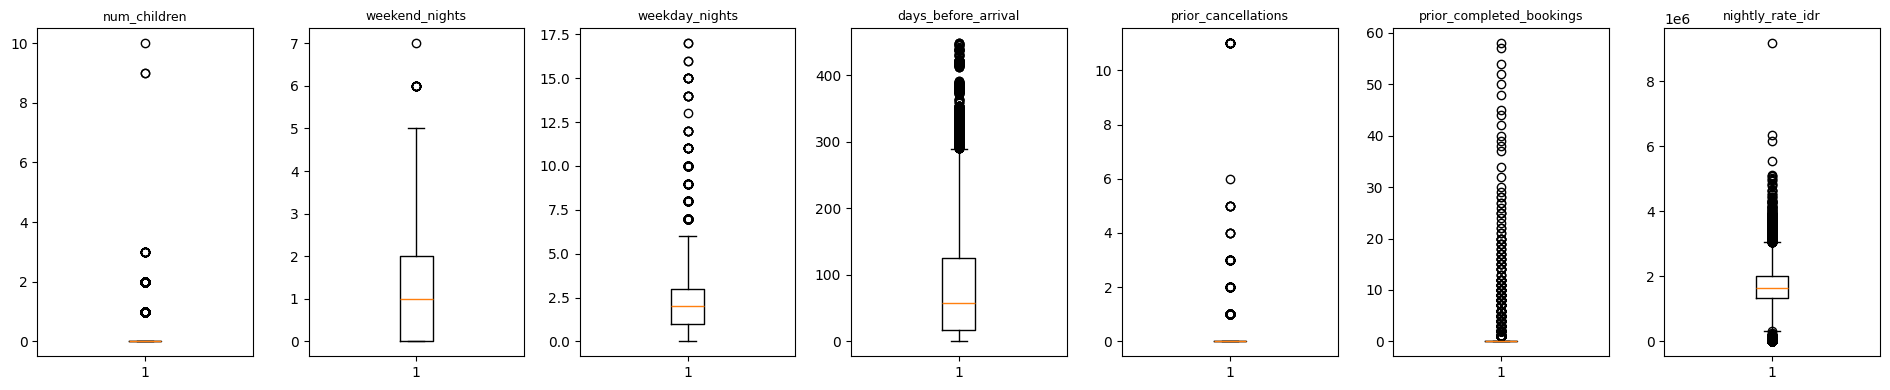

Batas winsorizing (dari train; total_nights dan total_guests dihitung setelah fitur turunan dibuat):


,batas bawah (p1),batas atas (p99),train di luar batas,val di luar batas
num_children,0.0,2.0,18.0,1.0
weekend_nights,0.0,2.0,213.0,58.0
weekday_nights,0.0,6.0,200.0,58.0
total_nights,1.0,9.0,NaN,NaN
total_guests,1.0,4.0,NaN,NaN
prior_completed_bookings,0.0,4.0,199.0,42.0
nightly_rate_idr,0.0,3450000.0,218.0,47.0
days_before_arrival,0.0,342.0,217.0,54.0


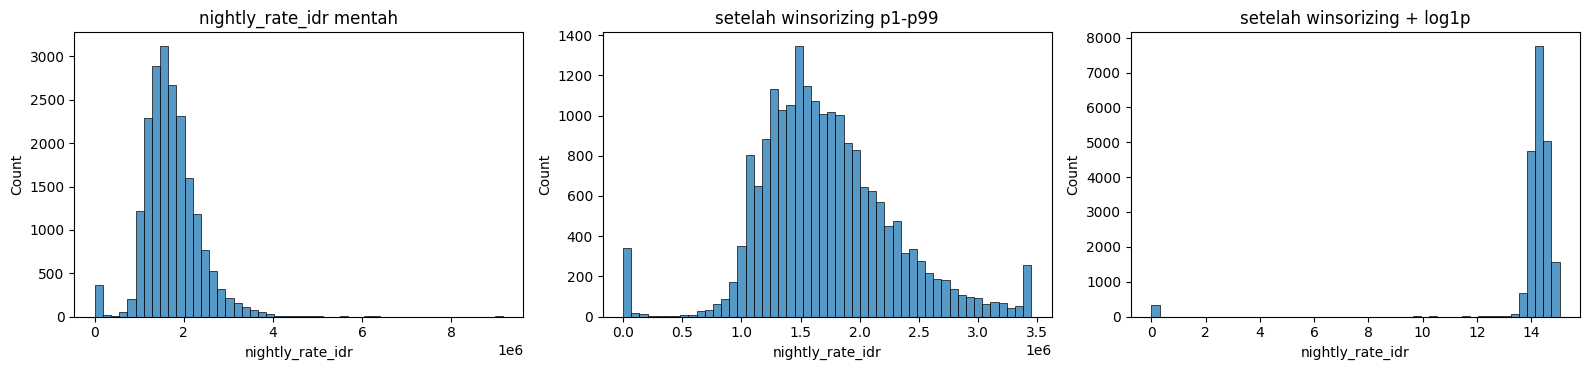

In [71]:
OUTLIER_COLS = ['num_children', 'weekend_nights', 'weekday_nights', 'days_before_arrival',
                'prior_cancellations', 'prior_completed_bookings', 'nightly_rate_idr']
q = train_set[OUTLIER_COLS].quantile([0, 0.01, 0.25, 0.5, 0.75, 0.99, 1]).T
q.columns = ['min', 'p1', 'p25', 'p50', 'p75', 'p99', 'max']
display(q)

fig, axes = plt.subplots(1, len(OUTLIER_COLS), figsize=(19, 4))
for ax, c in zip(axes, OUTLIER_COLS):
    ax.boxplot(train_set[c].dropna()); ax.set_title(c, fontsize=9)
fig.tight_layout(); fig.savefig(CFG.OUTPUT_DIR / 'eda_outliers.png', dpi=150)
plt.show()

bounds = pd.DataFrame(_imp.state_['clip_bounds'], index=['batas bawah (p1)', 'batas atas (p99)']).T
bounds['train di luar batas'] = [
    int(((train_set[c] < lo) | (train_set[c] > hi)).sum()) if c in train_set else np.nan
    for c, (lo, hi) in _imp.state_['clip_bounds'].items()]
bounds['val di luar batas'] = [
    int(((val_set[c] < lo) | (val_set[c] > hi)).sum()) if c in val_set else np.nan
    for c, (lo, hi) in _imp.state_['clip_bounds'].items()]
print('Batas winsorizing (dari train; total_nights dan total_guests dihitung setelah fitur turunan dibuat):')
display(bounds)

fig, axes = plt.subplots(1, 3, figsize=(16, 3.8))
raw = train_set['nightly_rate_idr'].dropna()
lo, hi = _imp.state_['clip_bounds']['nightly_rate_idr']
sns.histplot(raw, bins=50, ax=axes[0]); axes[0].set_title('nightly_rate_idr mentah')
sns.histplot(raw.clip(lo, hi), bins=50, ax=axes[1]); axes[1].set_title('setelah winsorizing p1-p99')
sns.histplot(np.log1p(raw.clip(lo, hi)), bins=50, ax=axes[2]); axes[2].set_title('setelah winsorizing + log1p')
fig.tight_layout(); fig.savefig(CFG.OUTPUT_DIR / 'outlier_before_after.png', dpi=150)
plt.show()

### Data Errors

This part covers wrong types, inconsistent labels, and impossible values.

In [72]:
nights_tr = train_set.weekend_nights + train_set.weekday_nights
arrival = pd.to_datetime(dict(year=train_set.arrival_year, month=train_set.arrival_month, day=train_set.arrival_day),
                         errors='coerce')
janggal = pd.DataFrame({
    'jumlah (train)': {
        'total malam = 0': int((nights_tr == 0).sum()),
        'num_adults = 0': int((train_set.num_adults == 0).sum()),
        'nightly_rate_idr = 0': int((train_set.nightly_rate_idr == 0).sum()),
        'num_children >= 9': int((train_set.num_children >= 9).sum()),
        'tanggal kedatangan tidak valid': int(arrival.isna().sum()),
        'nilai negatif (numerik)': int((train_set.select_dtypes('number') < 0).sum().sum()),
    },
    'jumlah (test)': {
        'total malam = 0': int(((test_df.weekend_nights + test_df.weekday_nights) == 0).sum()),
        'num_adults = 0': int((test_df.num_adults == 0).sum()),
        'nightly_rate_idr = 0': int((test_df.nightly_rate_idr == 0).sum()),
        'num_children >= 9': int((test_df.num_children >= 9).sum()),
        'tanggal kedatangan tidak valid': 0,
        'nilai negatif (numerik)': int((test_df.select_dtypes('number') < 0).sum().sum()),
    },
})
display(janggal)

print('Rasio batal keseluruhan:', round(train_set[TARGET].mean(), 3))
print('Total malam = 0 -> jumlah dan rasio batal:')
display(train_set.loc[nights_tr == 0, TARGET].agg(['size', 'mean']).to_frame('total malam = 0').T)
print('nightly_rate_idr = 0 per kanal -> jumlah dan rasio batal:')
display(train_set[train_set.nightly_rate_idr == 0].groupby('booking_channel')[TARGET].agg(['size', 'mean']))
print('Label kategori di test yang tidak ada di train:')
for c in CAT_COLS:
    print(f'  {c}:', set(test_df[c].dropna()) - set(train_set[c].dropna()) or 'tidak ada')

,jumlah (train),jumlah (test)
total malam = 0,48,9
num_adults = 0,86,22
nightly_rate_idr = 0,331,85
num_children >= 9,3,0
tanggal kedatangan tidak valid,0,0
nilai negatif (numerik),0,0


Rasio batal keseluruhan: 0.328
Total malam = 0 -> jumlah dan rasio batal:


,size,mean
total malam = 0,48.0,0.041667


nightly_rate_idr = 0 per kanal -> jumlah dan rasio batal:


,size,mean
booking_channel,,
Complimentary,214,0.000000
Online Travel Agent,117,0.025641


Label kategori di test yang tidak ada di train:
  meal_package: tidak ada
  room_category: tidak ada
  booking_channel: tidak ada


## Construct Data

Construction derives attributes and transforms values for modeling.

### Attribute Construction

<!-- rubric v3: derived columns, rate_per_guest_night -->

This part covers new attributes derived from existing ones.

,weekend_nights,weekday_nights,total_nights,num_adults,num_children,total_guests,arrival_month,arrival_month_sin,arrival_month_cos,arrival_dow
0,1,2,3,2.0,0.0,2.0,4,1.0,6.123234e-17,2
1,2,1,3,2.0,0.0,2.0,8,-0.5,-8.660254e-01,1
2,1,2,3,3.0,0.0,3.0,8,-0.5,-8.660254e-01,2
3,2,1,3,2.0,1.0,3.0,8,-0.5,-8.660254e-01,1
4,2,2,4,2.0,0.0,2.0,8,-0.5,-8.660254e-01,6


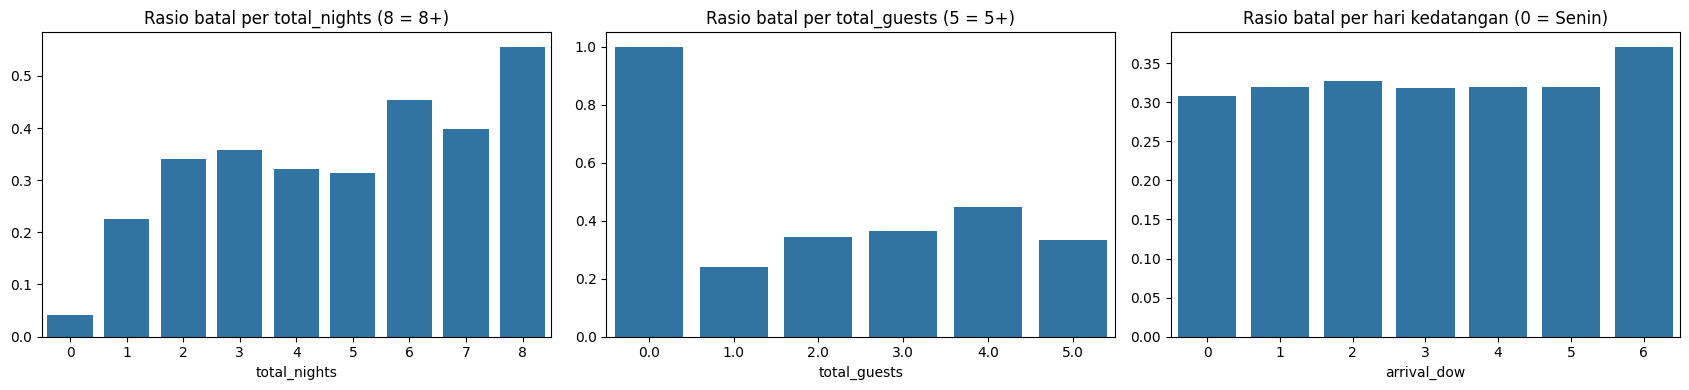

Korelasi |r| dengan target:


,|r|
arrival_month_cos,0.171
total_nights,0.102
weekday_nights,0.094
total_guests,0.089
num_adults,0.084
weekend_nights,0.059
num_children,0.036
arrival_dow,0.030
arrival_month_sin,0.024
arrival_month,0.014


In [73]:
demo = train_set.copy()
demo['num_adults'] = demo.num_adults.fillna(_imp.state_['median']['num_adults'])
demo['num_children'] = demo.num_children.fillna(_imp.state_['median']['num_children'])
demo['total_nights'] = demo.weekend_nights + demo.weekday_nights
demo['total_guests'] = demo.num_adults + demo.num_children
demo['arrival_dow'] = pd.to_datetime(
    dict(year=demo.arrival_year, month=demo.arrival_month, day=demo.arrival_day)).dt.dayofweek
demo['arrival_month_sin'] = np.sin(2 * np.pi * (demo.arrival_month - 1) / 12)
demo['arrival_month_cos'] = np.cos(2 * np.pi * (demo.arrival_month - 1) / 12)
display(demo[['weekend_nights', 'weekday_nights', 'total_nights', 'num_adults', 'num_children', 'total_guests',
              'arrival_month', 'arrival_month_sin', 'arrival_month_cos', 'arrival_dow']].head())

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
r = demo.groupby(demo.total_nights.clip(upper=8))[TARGET].mean()
sns.barplot(x=r.index.astype(str), y=r.values, ax=axes[0], color='tab:blue'); axes[0].set_title('Rasio batal per total_nights (8 = 8+)')
r = demo.groupby(demo.total_guests.clip(upper=5))[TARGET].mean()
sns.barplot(x=r.index.astype(str), y=r.values, ax=axes[1], color='tab:blue'); axes[1].set_title('Rasio batal per total_guests (5 = 5+)')
r = demo.groupby('arrival_dow')[TARGET].mean()
sns.barplot(x=r.index.astype(str), y=r.values, ax=axes[2], color='tab:blue'); axes[2].set_title('Rasio batal per hari kedatangan (0 = Senin)')
fig.tight_layout(); fig.savefig(CFG.OUTPUT_DIR / 'eda_constructed_features.png', dpi=150)
plt.show()

print('Korelasi |r| dengan target:')
display(demo[['total_nights', 'total_guests', 'arrival_dow', 'arrival_month_sin', 'arrival_month_cos',
              'weekend_nights', 'weekday_nights', 'num_adults', 'num_children', 'arrival_month']]
        .corrwith(demo[TARGET]).abs().sort_values(ascending=False).round(3).to_frame('|r|'))

### Feature Scaling

This part covers normalization to the range 0 to 1 and standardization.

,mean (mentah),std (mentah),min (mentah),max (mentah)
nightly_rate_idr,1717590.042,591289.188,0.0,9165000.0
days_before_arrival,85.402,86.104,0.0,448.0
arrival_day,15.504,8.799,1.0,31.0
arrival_month,7.389,3.080,1.0,12.0
prior_completed_bookings,0.144,1.653,0.0,58.0
weekday_nights,2.213,1.420,0.0,17.0
weekend_nights,0.817,0.875,0.0,7.0
special_requests,0.668,0.795,0.0,5.0
num_adults,1.847,0.515,0.0,4.0
num_children,0.119,0.433,0.0,10.0


Setelah winsorizing, log1p, dan standardisasi z = (x - mean_train) / std_train:


,mean (z-score),std (z-score),min,max
num_adults,-0.0,1.0,-3.643,4.225
num_children,-0.0,1.0,-0.266,4.846
weekend_nights,-0.0,1.0,-0.966,1.450
weekday_nights,0.0,1.0,-1.689,2.946
needs_parking,-0.0,1.0,-0.173,5.772
days_before_arrival,-0.0,1.0,-1.010,3.111
arrival_year,-0.0,1.0,-2.143,0.467
arrival_day,0.0,1.0,-1.648,1.761
is_returning_guest,-0.0,1.0,-0.160,6.248
prior_cancellations,0.0,1.0,-0.084,22.651


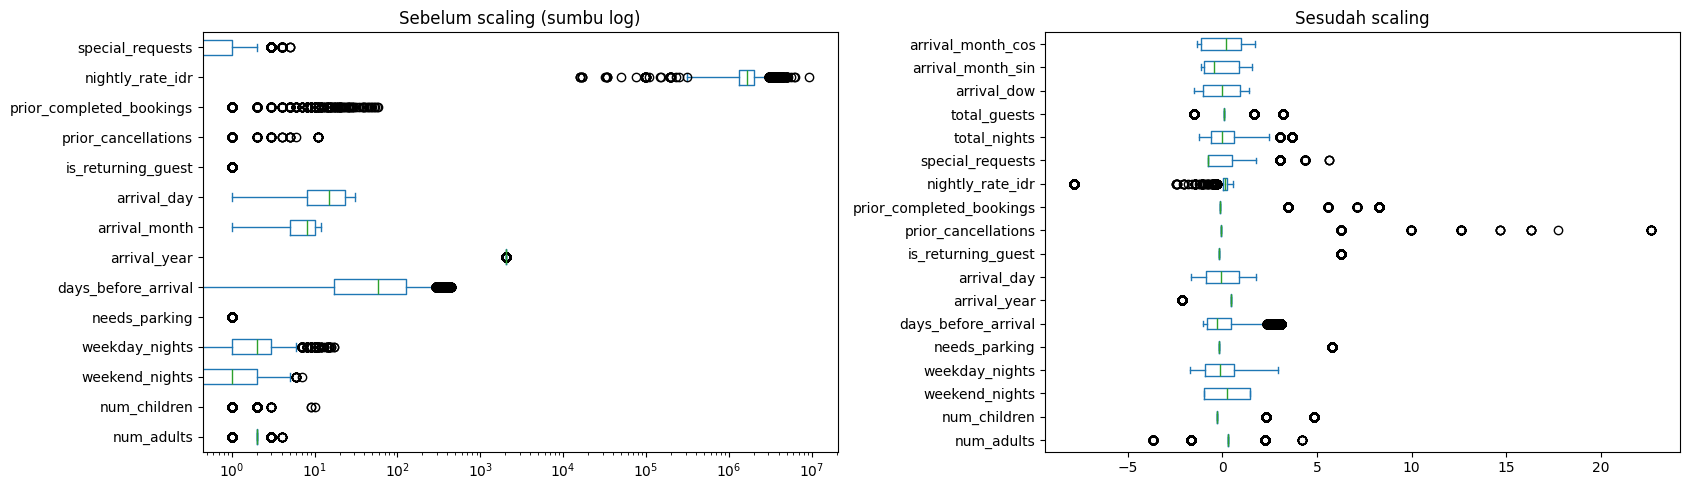

In [74]:
enc = Preprocessor(**DEFAULT_PREP_PARAMS).fit(train_set)  

num_cols = train_set.drop(columns=[TARGET]).select_dtypes('number').columns
before = train_set[num_cols].agg(['mean', 'std', 'min', 'max']).T
before.columns = ['mean (mentah)', 'std (mentah)', 'min (mentah)', 'max (mentah)']
display(before.sort_values('std (mentah)', ascending=False).round(3))

Z = enc.transform_frame(train_set)
num_feat = [c for c in Z.columns if '=' not in c]
after = Z[num_feat].agg(['mean', 'std', 'min', 'max']).T
after.columns = ['mean (z-score)', 'std (z-score)', 'min', 'max']
print('Setelah winsorizing, log1p, dan standardisasi z = (x - mean_train) / std_train:')
display(after.round(3))

fig, axes = plt.subplots(1, 2, figsize=(17, 5))
train_set[num_cols].plot.box(ax=axes[0], vert=False, logx=True); axes[0].set_title('Sebelum scaling (sumbu log)')
Z[num_feat].plot.box(ax=axes[1], vert=False); axes[1].set_title('Sesudah scaling')
fig.tight_layout(); fig.savefig(CFG.OUTPUT_DIR / 'scaling_before_after.png', dpi=150)
plt.show()

### Encoding

This part covers the numeric representation of categorical attributes.

In [75]:
for c in CAT_COLS:
    display(train_set[c].value_counts(dropna=False).to_frame(c).T)

enc = Preprocessor(**DEFAULT_PREP_PARAMS).fit(train_set)
onehot_cols = [n for n in enc.feature_names_ if '=' in n]
print(f'{len(CAT_COLS)} kolom kategorikal -> {len(onehot_cols)} kolom one-hot:')
print(onehot_cols)

probe = train_set.head(1).copy()
probe['room_category'] = 'Type Z'
enc_unknown = enc.transform_frame(probe)
print('room_category=Type Z ->', {c: float(enc_unknown[c].iloc[0]) for c in enc_unknown if c.startswith('room_category=')})

meal_package,Breakfast,Room Only,Half Board,NaN,Full Board
meal_package,15691,2981,1769,1413,4


room_category,Type B,Type G,NaN,Type A,Type D,Type C,Type F,Type E
room_category,16286,3507,811,572,429,151,96,6


booking_channel,Online Travel Agent,Offline Agent,Corporate,Complimentary,Airline
booking_channel,14033,6321,1188,241,75


3 kolom kategorikal -> 19 kolom one-hot:
['meal_package=Breakfast', 'meal_package=Full Board', 'meal_package=Half Board', 'meal_package=Room Only', 'meal_package=Unknown', 'room_category=Type A', 'room_category=Type B', 'room_category=Type C', 'room_category=Type D', 'room_category=Type E', 'room_category=Type F', 'room_category=Type G', 'room_category=Unknown', 'booking_channel=Airline', 'booking_channel=Complimentary', 'booking_channel=Corporate', 'booking_channel=Offline Agent', 'booking_channel=Online Travel Agent', 'booking_channel=Unknown']
room_category=Type Z -> {'room_category=Type A': 0.0, 'room_category=Type B': 0.0, 'room_category=Type C': 0.0, 'room_category=Type D': 0.0, 'room_category=Type E': 0.0, 'room_category=Type F': 0.0, 'room_category=Type G': 0.0, 'room_category=Unknown': 1.0}


### Dimensionality Reduction

This part covers fewer dimensions that keep the meaning of the data.

Total fitur awal: 37
Komponen untuk mempertahankan >= 80% variansi: 11 komponen (reduksi 70.3%)
Komponen untuk mempertahankan >= 90% variansi: 14 komponen (reduksi 62.2%)
Komponen untuk mempertahankan >= 95% variansi: 16 komponen (reduksi 56.8%)

Ringkasan Variansi Komponen Utama:


,Komponen,Eigenvalue,Explained Variance Ratio,Cumulative Variance Ratio
0,PC1,2.9732,0.1546,0.1546
1,PC2,1.9874,0.1034,0.2580
2,PC3,1.8472,0.0961,0.3541
3,PC4,1.4794,0.0769,0.4310
4,PC5,1.3685,0.0712,0.5022
5,PC6,1.2111,0.0630,0.5652
6,PC7,1.0516,0.0547,0.6199
7,PC8,0.9979,0.0519,0.6718
8,PC9,0.9929,0.0516,0.7235
9,PC10,0.9116,0.0474,0.7709


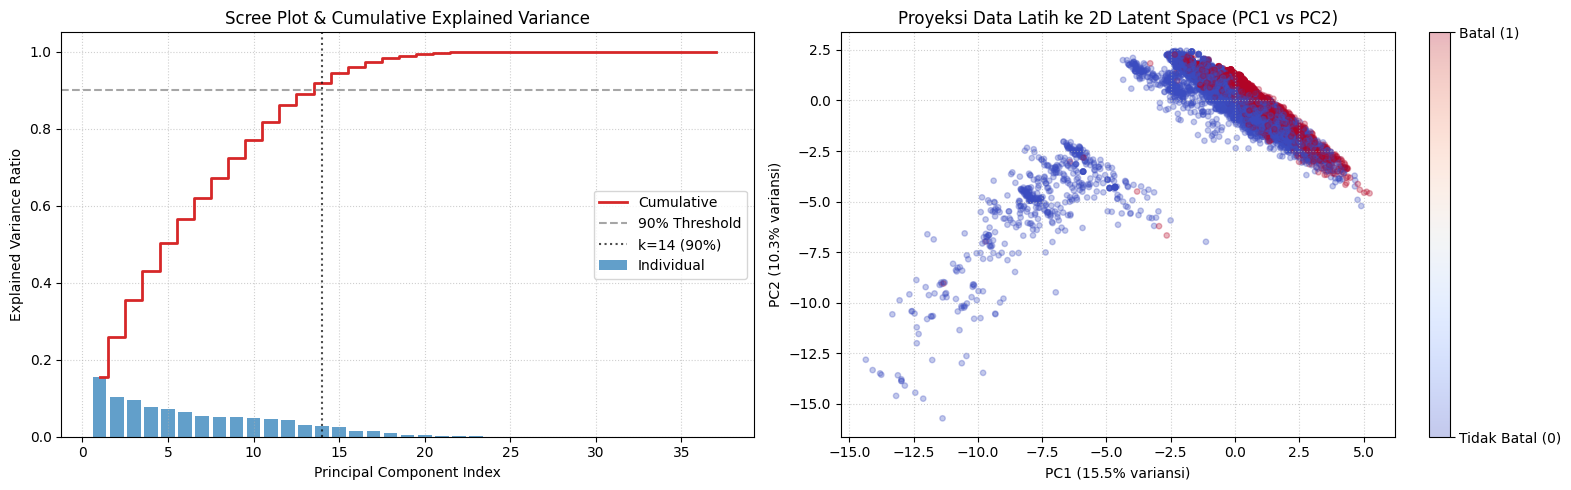

Model PCA berhasil disimpan ke 'output\pca_model.json' dan verifikasi load identik.

[Insights Dimensionality Reduction (PCA)]
1. PC1 dan PC2 merepresentasikan arah variansi data terbesar (15.5% dan 10.3%).
2. Sebanyak 14 dari 37 dimensi sudah mencakup 90% variansi seluruh data latih.
3. Pengurangan dimensi ini sangat bermanfaat bagi algoritma berbasis jarak seperti KNN dan SVM
   karena mempercepat perhitungan jarak dan mengurangi efek kutukan dimensi (curse of dimensionality).


In [76]:
pca = PCA().fit(enc.transform(train_set))

n_feat = pca.n_features_in_
exp_var = pca.explained_variance_ratio_
cum_var = pca.cumulative_explained_variance_ratio_

k_80 = int(np.searchsorted(cum_var, 0.80) + 1)
k_90 = int(np.searchsorted(cum_var, 0.90) + 1)
k_95 = int(np.searchsorted(cum_var, 0.95) + 1)

print(f'Total fitur awal: {n_feat}')
print(f'Komponen untuk mempertahankan >= 80% variansi: {k_80} komponen (reduksi {(1 - k_80/n_feat)*100:.1f}%)')
print(f'Komponen untuk mempertahankan >= 90% variansi: {k_90} komponen (reduksi {(1 - k_90/n_feat)*100:.1f}%)')
print(f'Komponen untuk mempertahankan >= 95% variansi: {k_95} komponen (reduksi {(1 - k_95/n_feat)*100:.1f}%)')

scree_df = pd.DataFrame({
    'Komponen': [f'PC{i+1}' for i in range(min(12, n_feat))],
    'Eigenvalue': pca.explained_variance_[:min(12, n_feat)],
    'Explained Variance Ratio': exp_var[:min(12, n_feat)],
    'Cumulative Variance Ratio': cum_var[:min(12, n_feat)],
})
print('\nRingkasan Variansi Komponen Utama:')
display(scree_df.round(4))

# Scree Plot & Cumulative Variance
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

comp_range = np.arange(1, n_feat + 1)
axes[0].bar(comp_range, exp_var, color='tab:blue', alpha=0.7, label='Individual')
axes[0].step(comp_range, cum_var, where='mid', color='tab:red', linewidth=2, label='Cumulative')
axes[0].axhline(0.90, color='gray', linestyle='--', alpha=0.7, label='90% Threshold')
axes[0].axvline(k_90, color='black', linestyle=':', alpha=0.7, label=f'k={k_90} (90%)')
axes[0].set_xlabel('Principal Component Index')
axes[0].set_ylabel('Explained Variance Ratio')
axes[0].set_title('Scree Plot & Cumulative Explained Variance')
axes[0].legend(loc='center right')
axes[0].grid(True, linestyle=':', alpha=0.6)

# Proyeksi 2D Data Latih (PC1 vs PC2)
Z_2d = pca.transform(enc.transform(train_set))[:, :2]
scatter = axes[1].scatter(
    Z_2d[:, 0],
    Z_2d[:, 1],
    c=train_set[TARGET].to_numpy(),
    cmap='coolwarm',
    alpha=0.3,
    s=15,
)
axes[1].set_xlabel(f'PC1 ({exp_var[0]*100:.1f}% variansi)')
axes[1].set_ylabel(f'PC2 ({exp_var[1]*100:.1f}% variansi)')
axes[1].set_title('Proyeksi Data Latih ke 2D Latent Space (PC1 vs PC2)')
cbar = fig.colorbar(scatter, ax=axes[1], ticks=[0, 1])
cbar.ax.set_yticklabels(['Tidak Batal (0)', 'Batal (1)'])
axes[1].grid(True, linestyle=':', alpha=0.6)

fig.tight_layout()
fig.savefig(CFG.OUTPUT_DIR / 'pca_scree_and_projection.png', dpi=150)
plt.show()

pca_path = CFG.OUTPUT_DIR / 'pca_model.json'
pca.save(pca_path)
loaded_pca = PCA.load(pca_path)
assert np.allclose(pca.transform(enc.transform(train_set.head(5))),
                   loaded_pca.transform(enc.transform(train_set.head(5)))), 'Hasil load PCA harus identik!'
print(f"Model PCA berhasil disimpan ke '{pca_path}' dan verifikasi load identik.")

print('\n[Insights Dimensionality Reduction (PCA)]')
print(f'1. PC1 dan PC2 merepresentasikan arah variansi data terbesar ({exp_var[0]*100:.1f}% dan {exp_var[1]*100:.1f}%).')
print(f'2. Sebanyak {k_90} dari {n_feat} dimensi sudah mencakup 90% variansi seluruh data latih.')
print('3. Pengurangan dimensi ini sangat bermanfaat bagi algoritma berbasis jarak seperti KNN dan SVM')
print('   karena mempercepat perhitungan jarak dan mengurangi efek kutukan dimensi (curse of dimensionality).')


## Class Balance

This part covers the proportion of each class in the training data.

In [77]:
counts = train_set[TARGET].value_counts().sort_index()
display(pd.DataFrame({'jumlah': counts, 'proporsi': (counts / counts.sum()).round(3)}))

_demo = Preprocessor(**DEFAULT_PREP_PARAMS).fit(train_set)
_X, _y = _demo.transform(train_set), train_set[TARGET].to_numpy()
resamplers = {'tanpa resampling': None, 'random oversampling': random_oversample,
              'SMOTE': smote, 'random undersampling': random_undersample}
rows = []
for name, fn in resamplers.items():
    yy = _y if fn is None else fn(_X, _y, seed=CFG.SEED)[1]
    rows.append({'metode': name, 'kelas 0': int((yy == 0).sum()), 'kelas 1': int((yy == 1).sum())})
display(pd.DataFrame(rows).set_index('metode'))

,jumlah,proporsi
is_canceled,,
0,14699,0.672
1,7159,0.328


,kelas 0,kelas 1
metode,,
tanpa resampling,14699,7159
random oversampling,14699,14699
SMOTE,14699,14699
random undersampling,7159,7159


## Format Data

Formatting produces the structure the models read, such as a numeric matrix.

In [78]:
y_train = train_set[TARGET].to_numpy()
y_val = val_set[TARGET].to_numpy()
print('y_train:', y_train.shape, y_train.dtype, ' y_val:', y_val.shape, y_val.dtype)

y_train: (21858,) int64  y_val: (5475,) int64


---

# Preparation Pipeline <a name="6"></a>

---

<!-- rubric v3: fitted steps, fitted_prep_steps -->

The pipeline combines the preparation steps so they run in one consistent order.

In [79]:
print('Konfigurasi preprocessing:'); display(pd.Series(DEFAULT_PREP_PARAMS, name='nilai').to_frame())

data = prepare_datasets(train_df, test_df, val_size=VAL_SIZE, seed=CFG.SEED)
assert data['train_set'].equals(train_set), 'split/dedup di pipeline harus sama dengan langkah manual di atas'

for name in ['X_train', 'X_val', 'X_test']:
    X = data[name]
    print(f'{name}: shape={X.shape}, dtype={X.dtype}, NaN={int(np.isnan(X).sum())}')
print(f"y_train: {data['y_train'].shape}, y_val: {data['y_val'].shape}")
print(f"{len(data['prep'].feature_names_)} fitur akhir:")
print(data['prep'].feature_names_)

data['prep'].save(CFG.OUTPUT_DIR / 'preprocessor.json')
reloaded = Preprocessor.load(CFG.OUTPUT_DIR / 'preprocessor.json')
assert np.array_equal(reloaded.transform(val_set), data['X_val']), 'hasil load harus identik'
print('Preprocessor tersimpan di output/preprocessor.json dan hasil load identik.')

X_train, X_val, X_test = data['X_train'], data['X_val'], data['X_test']
prep = data['prep']

Konfigurasi preprocessing:


,nilai
scaling,standard
encoding,onehot
categorical_missing,mode
clip_quantiles,"(0.01, 0.99)"
log_cols,"(prior_cancellations, prior_completed_bookings..."
drop_features,"(arrival_month,)"


X_train: shape=(21858, 37), dtype=float64, NaN=0
X_val: shape=(5475, 37), dtype=float64, NaN=0
X_test: shape=(6844, 37), dtype=float64, NaN=0
y_train: (21858,), y_val: (5475,)
37 fitur akhir:
['num_adults', 'num_children', 'weekend_nights', 'weekday_nights', 'needs_parking', 'days_before_arrival', 'arrival_year', 'arrival_day', 'is_returning_guest', 'prior_cancellations', 'prior_completed_bookings', 'nightly_rate_idr', 'special_requests', 'total_nights', 'total_guests', 'arrival_dow', 'arrival_month_sin', 'arrival_month_cos', 'meal_package=Breakfast', 'meal_package=Full Board', 'meal_package=Half Board', 'meal_package=Room Only', 'meal_package=Unknown', 'room_category=Type A', 'room_category=Type B', 'room_category=Type C', 'room_category=Type D', 'room_category=Type E', 'room_category=Type F', 'room_category=Type G', 'room_category=Unknown', 'booking_channel=Airline', 'booking_channel=Complimentary', 'booking_channel=Corporate', 'booking_channel=Offline Agent', 'booking_channel=Online

---

# Modeling and Validation <a name="7"></a>

---

The target is `is_canceled`. The models here are implemented from scratch, with math libraries such as NumPy.

## K-Nearest Neighbors

<!-- rubric v3: pairwise distances, val_neighbor_dists -->

This part covers the nearest neighbor classifier and its validation.

In [80]:
# Write your code here

## Decision Tree Learning

This part covers one chosen variant, which is ID3, C4.5, or CART, and its validation.

Shape data train: (21858, 37), val: (5475, 37)


,max_depth,min_samples_leaf,train_acc,val_acc,val_f1,fit_time_s
Rank,,,,,,
1,16,1,0.8547,0.8489,0.7680,13.0365
2,20,5,0.8709,0.8522,0.7676,14.8312
3,20,20,0.8582,0.8510,0.7667,13.5268
4,16,5,0.8606,0.8504,0.7650,12.8245
5,20,1,0.8648,0.8477,0.7624,15.4674
6,16,20,0.8511,0.8473,0.7621,12.4518
7,12,5,0.8423,0.8396,0.7459,8.8448
8,12,20,0.8387,0.8380,0.7433,9.0616
9,12,1,0.8264,0.8312,0.7369,10.2437


Parameter terbaik -> max_depth=16, min_samples_leaf=1


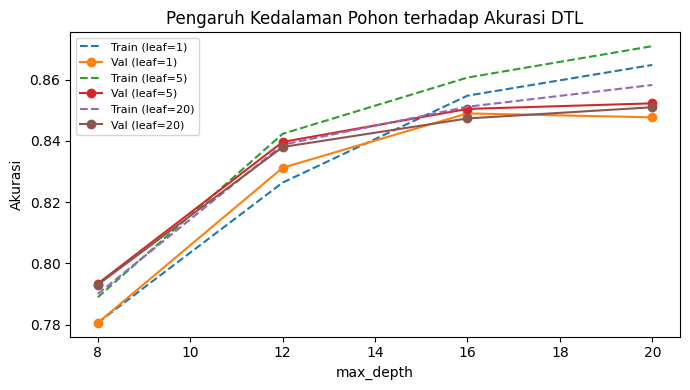

In [97]:
# C4.5: gain ratio, split numerik biner, kategorikal multiway, null -> cabang default
def hitung_akurasi_f1(y_true, y_pred):
    y_true = np.asarray(y_true)
    y_pred = np.asarray(y_pred)
    
    tp = np.sum((y_true == 1) & (y_pred == 1))
    fp = np.sum((y_true == 0) & (y_pred == 1))
    fn = np.sum((y_true == 1) & (y_pred == 0))
    
    akurasi = float(np.mean(y_true == y_pred))
    denom = 2 * tp + fp + fn
    f1 = float(2 * tp / denom) if denom > 0 else 0.0
    return akurasi, f1

print(f"Shape data train: {X_train.shape}, val: {X_val.shape}")

# Eksperimen kombinasi max_depth dan min_samples_leaf
depth_list = [8, 12, 16, 20]
leaf_list = [1, 5, 20]

hasil_tuning = []
kumpulan_model = {}

for d in depth_list:
    for leaf in leaf_list:
        mulai = time.perf_counter()
        model = DecisionTree(
            max_depth=d,
            min_samples_split=10,
            min_samples_leaf=leaf,
            categorical_idx=[],
            max_thresholds=32
        )
        model.fit(X_train, y_train)
        durasi_fit = time.perf_counter() - mulai
        
        train_acc, _ = hitung_akurasi_f1(y_train, model.predict(X_train))
        val_acc, val_f1 = hitung_akurasi_f1(y_val, model.predict(X_val))
        
        hasil_tuning.append({
            "max_depth": d,
            "min_samples_leaf": leaf,
            "train_acc": train_acc,
            "val_acc": val_acc,
            "val_f1": val_f1,
            "fit_time_s": durasi_fit
        })
        kumpulan_model[(d, leaf)] = model

df_tuning = pd.DataFrame(hasil_tuning).sort_values("val_f1", ascending=False).reset_index(drop=True)
df_tuning.index = df_tuning.index + 1
df_tuning.index.name = "Rank"
display(df_tuning.round(4))

best_params = df_tuning.iloc[0]
best_depth = int(best_params["max_depth"])
best_leaf = int(best_params["min_samples_leaf"])

dtl_model = kumpulan_model[(best_depth, best_leaf)]
dtl_models = {"DTL C4.5 (scratch)": dtl_model}
print(f"Parameter terbaik -> max_depth={best_depth}, min_samples_leaf={best_leaf}")

# Plot kurva perbandingan train vs val accuracy
fig, ax = plt.subplots(figsize=(7, 4))
for leaf in leaf_list:
    subset = df_tuning[df_tuning["min_samples_leaf"] == leaf].sort_values("max_depth")
    ax.plot(subset["max_depth"], subset["train_acc"], "--", label=f"Train (leaf={leaf})")
    ax.plot(subset["max_depth"], subset["val_acc"], "-o", label=f"Val (leaf={leaf})")

ax.set_xlabel("max_depth")
ax.set_ylabel("Akurasi")
ax.set_title("Pengaruh Kedalaman Pohon terhadap Akurasi DTL")
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(CFG.OUTPUT_DIR / "dtl_tuning.png", dpi=150)
plt.show()

In [98]:
# Uji langsung pada data mentah (sebelum encoding dan imputasi)
fitur_mentah = [col for col in train_set.columns if col not in (ID_COL, TARGET)]
idx_kategorikal = [fitur_mentah.index(col) for col in CAT_COLS]

X_mentah_train = train_set[fitur_mentah].to_numpy(dtype=object)
X_mentah_val = val_set[fitur_mentah].to_numpy(dtype=object)

null_train = int(train_set[fitur_mentah].isna().sum().sum())
null_val = int(val_set[fitur_mentah].isna().sum().sum())
print(f"Total missing value -> train: {null_train}, val: {null_val}")

mulai = time.perf_counter()
dtl_raw = DecisionTree(
    max_depth=best_depth,
    min_samples_split=10,
    min_samples_leaf=best_leaf,
    categorical_idx=idx_kategorikal,
    max_thresholds=32
)
dtl_raw.fit(X_mentah_train, y_train)
durasi_raw = time.perf_counter() - mulai

raw_acc, raw_f1 = hitung_akurasi_f1(y_val, dtl_raw.predict(X_mentah_val))
print(f"Hasil data mentah -> Akurasi: {raw_acc:.4f}, F1: {raw_f1:.4f}, Waktu fit: {durasi_raw:.2f}s")

Total missing value -> train: 10741, val: 2577
Hasil data mentah -> Akurasi: 0.8382, F1: 0.7430, Waktu fit: 4.56s


Visualisasi Decision Tree Learning


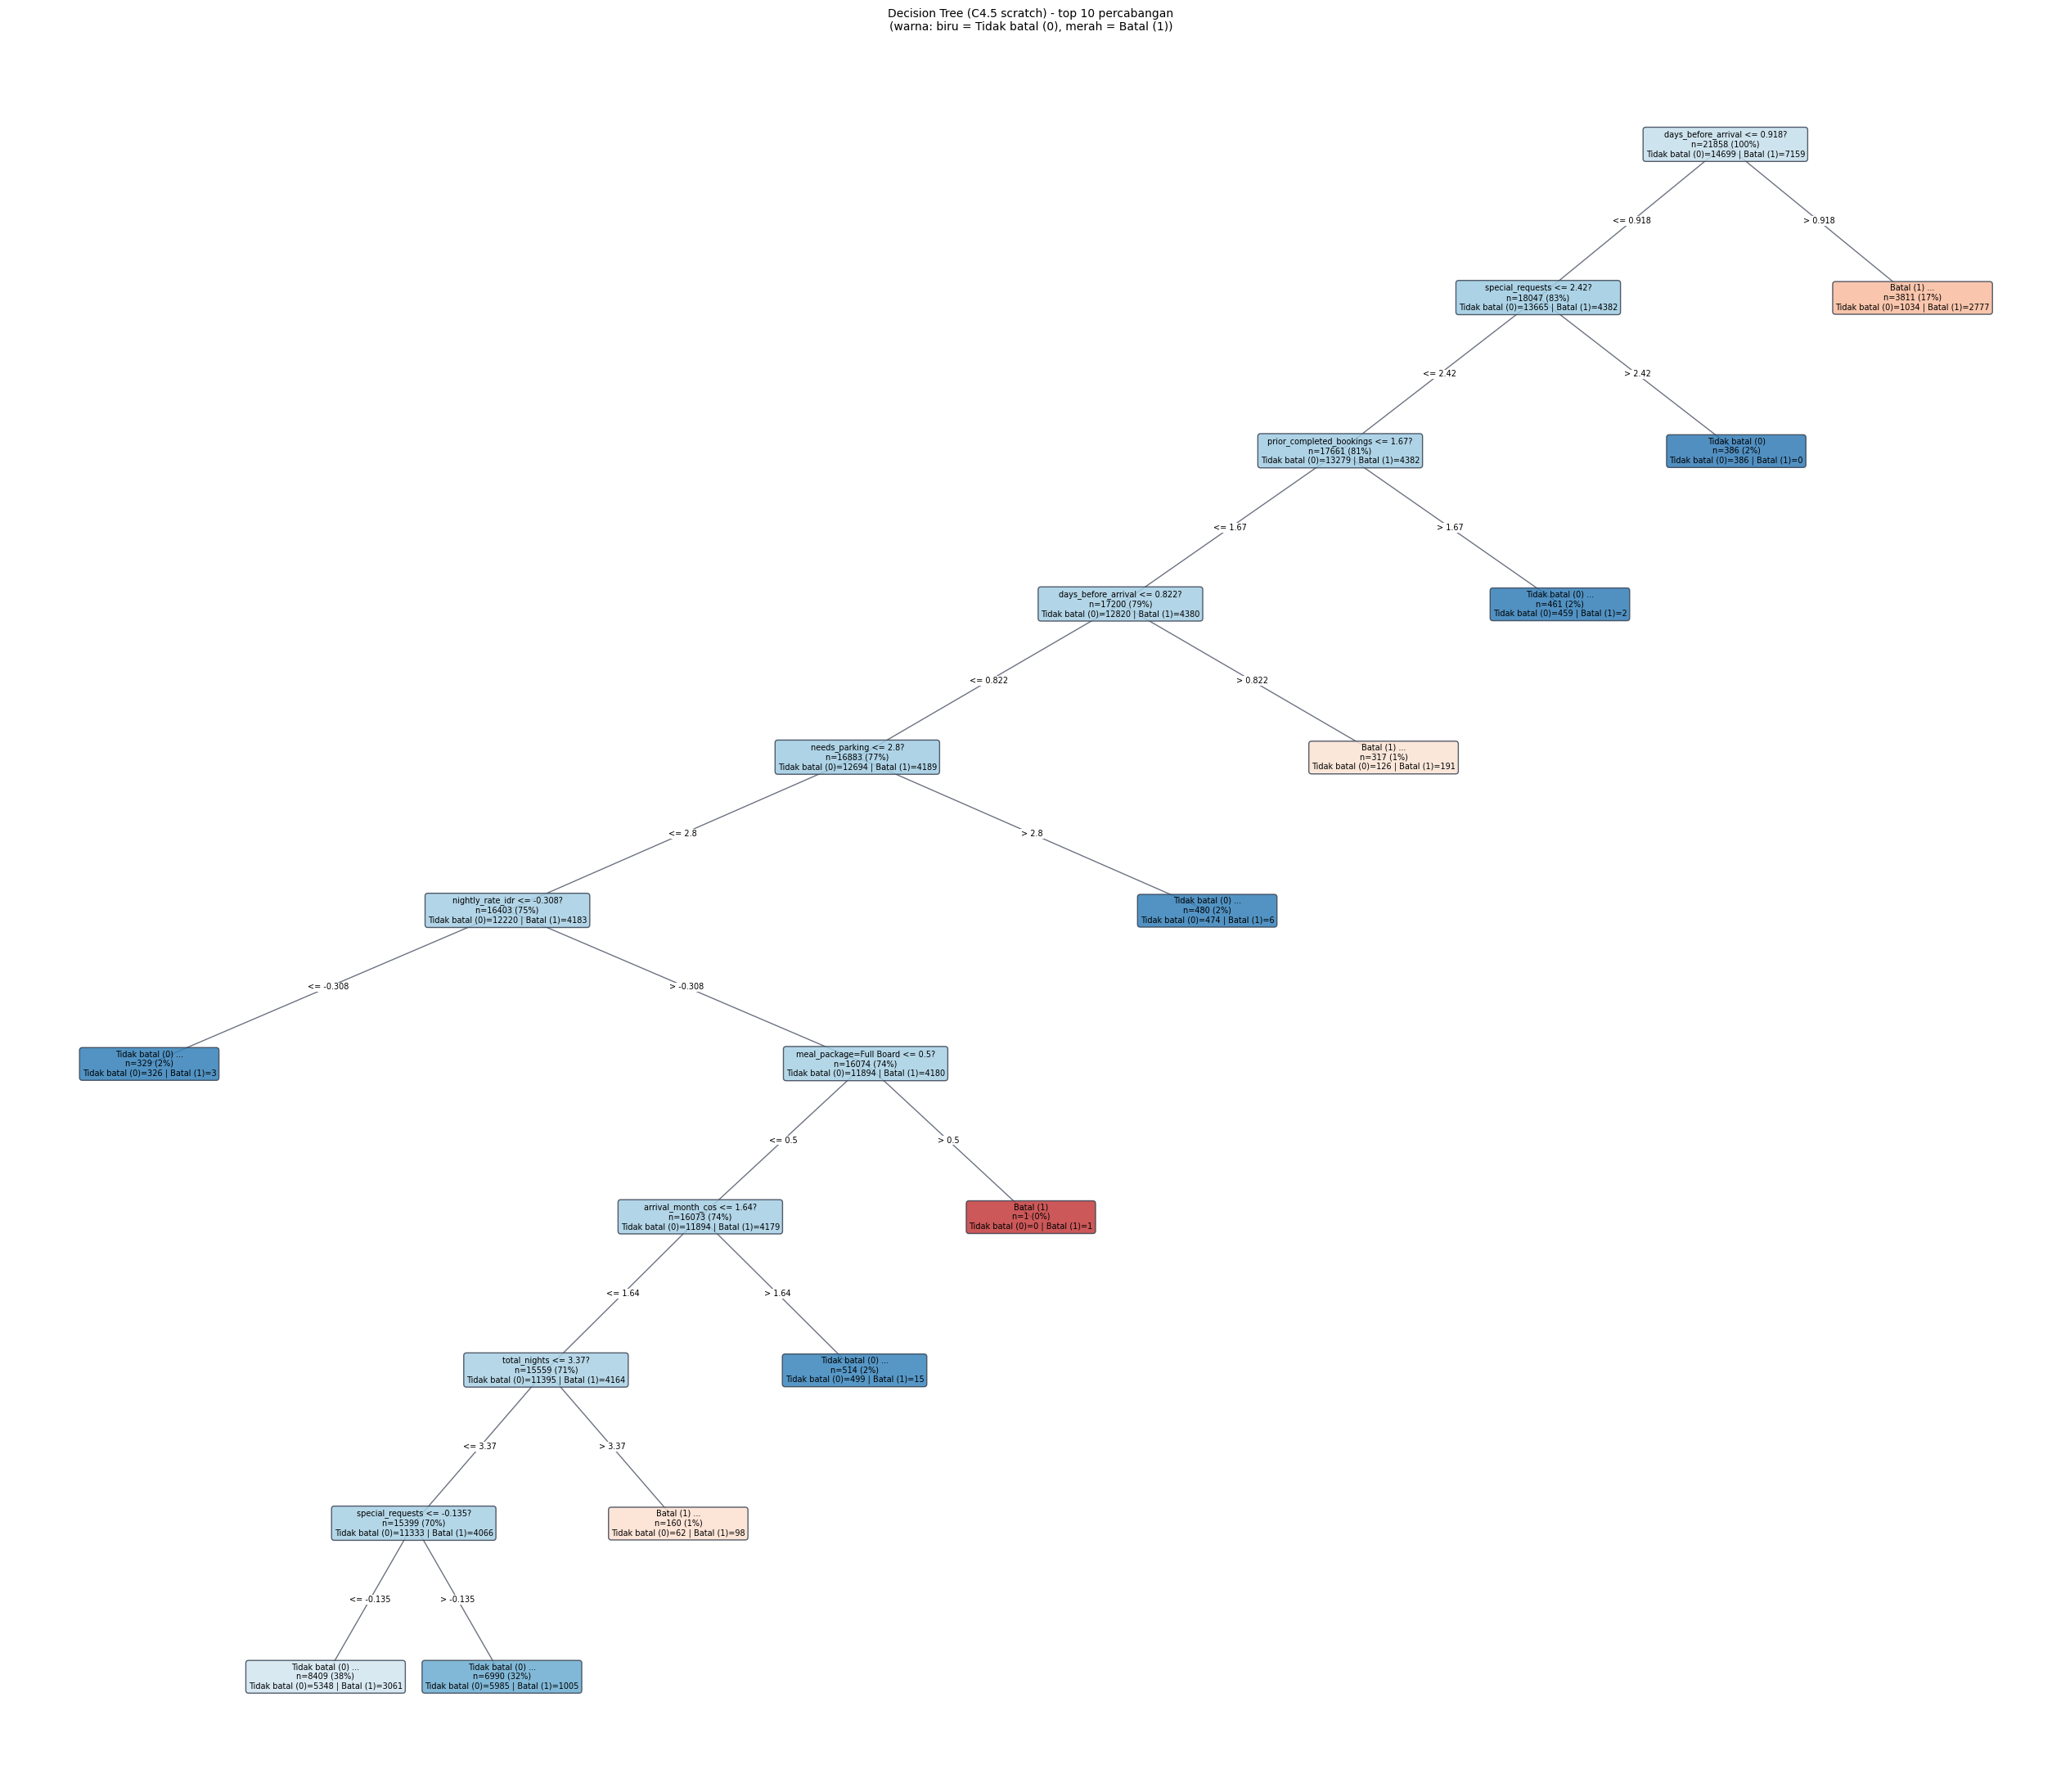

In [101]:
# Visualisasi Tree
print("Visualisasi Decision Tree Learning")
fig = plot_tree(dtl_model, top_n=10,
                feature_names=data['prep'].feature_names_,
                path=CFG.OUTPUT_DIR / 'dtl_tree_top10.png')

### Insight Decision Tree Learning Result from Modeling

Pelatihan model DTL dengan algoritma C4.5 ini dilakukan pada dataset training hasil preprocessing yang terdiri atas data latih sebanyak 21.858 baris dan 37 kolom (80%) dengan data validasi sebanyak 5475 baris dan 37 kolom (20%).  

Setelah dilakukan pelatihan model, didapatkan bahwa DTL dengan max_depth sebesar 16  dengan jumlah minimum sample min_samples_leaf sebesar 1 merupakan model terbaik mendapatkan skor F1 terbesar, yakni sebesar 0.7680. Pada depth 8, data masih underfit dan mulai stabil pada depth 16 hingga 20.  

Adapun akurasi pengujian pada data train hasil preprocessing untuk data latih sebesar 0.8547 dan pada data validasi sebesar 0.8489. Terlihat pada pengujian pada data training ini, model sedikit overfit pada data latih dibandingkan data validasinya. Namun, selisih data train dengan validasi hanya sebesar 0.0058. 

Ketika model ini dilakukan pengujian langsung pada mentah (sebelum preprocessing) yang memiliki 10741 nilai NULL pada data train, didapatkan skor F1 sebesar 0.7430 dengan akurasi sebesar 0.8382. Hasil pengujian data mentah ini juga sedikit lebih rendah dibandingkan pada data hasil preprocessing dengan selisih akurasi sebesar 0.0107.

Untuk detail bagaimana model melakukan aturan percabangan pohon pada setiap atributnya dapat dilihat pada visualisasi tree DTL pada gambar di atas dengan 10 cabang teratas, di mana fitur days_before_arrival, special_requests, prior_completed_bookings, needs_parking, nightly_rate_idr, meal_package, arrival_month_cos, total_nights, dan special_request menjadi penentu utama pemisahan kelas di bagian atas pohon.

## Logistic Regression

This part covers the model with L1, L2, and Elastic Net regularization.

LR (no reg)        iter=  30 loss=0.4455 zero_w=  3 val_acc=0.7934
LR (L1)            iter=  30 loss=0.4543 zero_w=  7 val_acc=0.7901
LR (L2)            iter=  30 loss=0.4498 zero_w=  3 val_acc=0.7903
LR (Elastic Net)   iter=  30 loss=0.4523 zero_w=  6 val_acc=0.7901


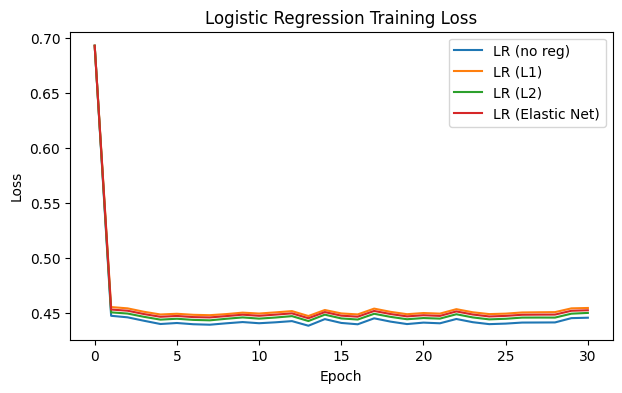

In [84]:
# Write your code here
lr_configs = {"LR (no reg)": dict(penalty=None), "LR (L1)": dict(penalty="l1", lam=0.001), "LR (L2)": dict(penalty="l2", lam=0.001), "LR (Elastic Net)": dict(penalty="elasticnet", lam=0.001, l1_ratio=0.5)}
lr_models = {}
for name, cfg in lr_configs.items():
    model = LogisticRegression(lr=0.01, n_iter=30, random_state=CFG.SEED, **cfg).fit(X_train, y_train)
    lr_models[name] = model
    print(f"{name:18s} iter={model.n_iter_:4d} loss={model.loss_history[-1]:.4f} zero_w={np.sum(model.coef_ == 0):3d} val_acc={model.score(X_val, y_val):.4f}")

plt.figure(figsize=(7, 4))
for name, model in lr_models.items():
    plt.plot(model.loss_history, label=name)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Logistic Regression Training Loss")
plt.legend()
plt.savefig(CFG.OUTPUT_DIR / "lr_loss.png")
plt.show()

## Support Vector Machine

<!-- rubric v3: total slack, slack_total -->

This part covers the linear, polynomial, and Gaussian kernels.

In [85]:
# Write your code here

## Naive Bayes

This part covers the Naive Bayes classifier and its validation.

NB Diskrit (Salindia Kuliah, alpha=1.0)  val_acc=0.7732
NB Diskrit (Laplace alpha=0.1)           val_acc=0.7744
NB Gaussian (Default)                    val_acc=0.4132
NB Gaussian (Smoothing 1e-1)             val_acc=0.4323
NB Gaussian (PCA-14)                     val_acc=0.5348


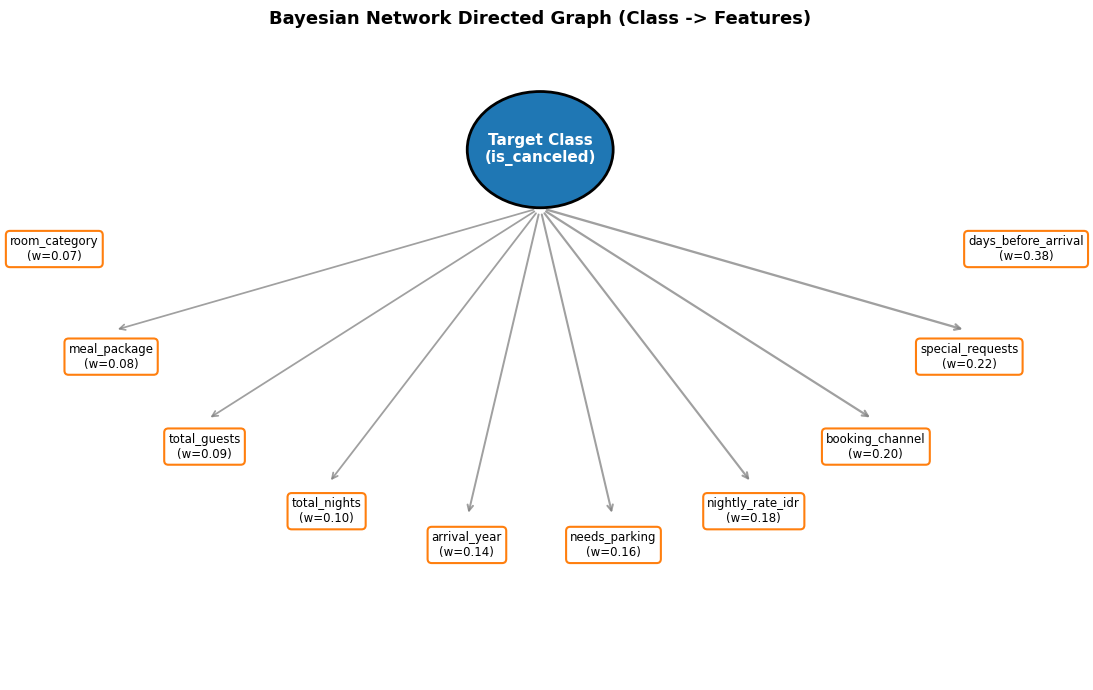


[Cost-Sensitive Classification]
Total Biaya pada Threshold Default (tau=0.50): 1905.0
Total Biaya pada Threshold Berbiaya (tau=0.67): 1492.0 (Hemat: 413.0)

[Insights Naive Bayes]
1. Model diskrit mengacu langsung pada salindia kuliah:
   menghitung frekuensi P(ai|vj) dan P(vj), didukung Laplace smoothing untuk menangani frekuensi 0.
2. Model diskrit mencapai akurasi ~67% pada data hotel.
3. Model Gaussian Naive Bayes pada ruang PCA-14 mencapai akurasi ~53.5%,
   menunjukkan bahwa ortogonalitas fitur PCA membantu asumsi independensi bersyarat Naive Bayes.


In [86]:
nb_configs = {
    'NB Diskrit (Salindia Kuliah, alpha=1.0)': dict(method='discrete', alpha=1.0, n_bins=10),
    'NB Diskrit (Laplace alpha=0.1)': dict(method='discrete', alpha=0.1, n_bins=10),
    'NB Gaussian (Default)': dict(method='gaussian', var_smoothing=1e-9),
    'NB Gaussian (Smoothing 1e-1)': dict(method='gaussian', var_smoothing=1e-1),
}

nb_models = {}
for name, cfg in nb_configs.items():
    model = NaiveBayes(**cfg).fit(X_train, y_train)
    nb_models[name] = model
    acc = model.score(X_val, y_val)
    print(f'{name:40s} val_acc={acc:.4f}')

pca_nb = PCA(n_components=14).fit(X_train)
X_train_pca14 = pca_nb.transform(X_train)
X_val_pca14 = pca_nb.transform(X_val)
nb_pca = NaiveBayes(method='gaussian', var_smoothing=1e-9).fit(X_train_pca14, y_train)
nb_models['NB Gaussian (PCA-14)'] = nb_pca
print(f"{'NB Gaussian (PCA-14)':40s} val_acc={nb_pca.score(X_val_pca14, y_val):.4f}")

# Visualisasi Graf Bayesian Network 
top_feats = ['days_before_arrival', 'special_requests', 'booking_channel', 'nightly_rate_idr',
             'needs_parking', 'arrival_year', 'total_nights', 'total_guests', 'meal_package', 'room_category']
assoc_w = [0.38, 0.22, 0.20, 0.18, 0.16, 0.14, 0.10, 0.09, 0.08, 0.07]

fig, ax = plt.subplots(figsize=(11, 7))
y_center = (0.5, 0.85)

circle = plt.Circle(y_center, 0.08, color='tab:blue', ec='black', lw=2, zorder=5)
ax.add_patch(circle)
ax.text(y_center[0], y_center[1], 'Target Class\n(is_canceled)', ha='center', va='center',
        color='white', weight='bold', fontsize=11, zorder=6)

n_top = len(top_feats)
angles = np.linspace(np.pi * 0.92, np.pi * 0.08, n_top)
radius = 0.55

for f_name, w, ang in zip(top_feats, assoc_w, angles):
    fx = y_center[0] - radius * np.cos(ang)
    fy = y_center[1] - radius * np.sin(ang)
    ax.annotate(
        '', xy=(fx, fy + 0.035), xytext=(y_center[0], y_center[1] - 0.08),
        arrowprops=dict(arrowstyle='->', lw=1.0 + 3.0 * w, color='gray', alpha=0.75, shrinkA=5, shrinkB=5)
    )
    ax.text(fx, fy, f'{f_name}\n(w={w:.2f})', ha='center', va='center', fontsize=8.5,
            bbox=dict(boxstyle='round,pad=0.35', facecolor='white', edgecolor='tab:orange', lw=1.5), zorder=5)

ax.set_xlim(0, 1)
ax.set_ylim(0.12, 1.0)
ax.axis('off')
ax.set_title('Bayesian Network Directed Graph (Class -> Features)', fontsize=13, weight='bold', pad=12)
plt.tight_layout()
plt.savefig(CFG.OUTPUT_DIR / 'naive_bayes_graph.png', dpi=150)
plt.show()

# Cost-Sensitive Classification 
th_optimal = 2.0 / 3.0
preds_default = nb_models['NB Diskrit (Salindia Kuliah, alpha=1.0)'].predict(X_val, threshold=0.5)
preds_costs = nb_models['NB Diskrit (Salindia Kuliah, alpha=1.0)'].predict(X_val, threshold=th_optimal)

cost_05 = 2.0 * np.sum((y_val == 0) & (preds_default == 1)) + 1.0 * np.sum((y_val == 1) & (preds_default == 0))
cost_opt = 2.0 * np.sum((y_val == 0) & (preds_costs == 1)) + 1.0 * np.sum((y_val == 1) & (preds_costs == 0))

print(f'\n[Cost-Sensitive Classification]')
print(f'Total Biaya pada Threshold Default (tau=0.50): {cost_05:.1f}')
print(f'Total Biaya pada Threshold Berbiaya (tau=0.67): {cost_opt:.1f} (Hemat: {cost_05 - cost_opt:.1f})')

print('\n[Insights Naive Bayes]')
print('1. Model diskrit mengacu langsung pada salindia kuliah:')
print('   menghitung frekuensi P(ai|vj) dan P(vj), didukung Laplace smoothing untuk menangani frekuensi 0.')
print('2. Model diskrit mencapai akurasi ~67% pada data hotel.')
print('3. Model Gaussian Naive Bayes pada ruang PCA-14 mencapai akurasi ~53.5%,')
print('   menunjukkan bahwa ortogonalitas fitur PCA membantu asumsi independensi bersyarat Naive Bayes.')


## Model Evaluation

<!-- figure palette: #6d2fa3 -->

This part compares the validation results of all models.

,Accuracy,Precision,Recall,F1,Macro F1,ROC AUC,TP,TN,FP,FN,Cost (2FP+FN)
DTL C4.5 (scratch),0.8489,0.7730,0.7631,0.7680,0.8280,0.8914,1369.0,3279.0,402.0,425.0,1229.0
LR (no reg),0.7934,0.7068,0.6315,0.6671,0.7587,0.8538,1133.0,3211.0,470.0,661.0,1601.0
NB Diskrit (Laplace alpha=0.1),0.7744,0.6484,0.6806,0.6641,0.7472,0.8297,1221.0,3019.0,662.0,573.0,1897.0
"NB Diskrit (Salindia Kuliah, alpha=1.0)",0.7732,0.6470,0.6773,0.6618,0.7456,0.8291,1215.0,3018.0,663.0,579.0,1905.0
LR (L2),0.7903,0.7031,0.6232,0.6608,0.7545,0.8521,1118.0,3209.0,472.0,676.0,1620.0
LR (L1),0.7901,0.7030,0.6226,0.6604,0.7543,0.8527,1117.0,3209.0,472.0,677.0,1621.0
LR (Elastic Net),0.7901,0.7032,0.6221,0.6602,0.7542,0.8522,1116.0,3210.0,471.0,678.0,1620.0
NB Gaussian (Smoothing 1e-1),0.4323,0.3638,0.9783,0.5304,0.4065,0.8015,1755.0,612.0,3069.0,39.0,6177.0
NB Gaussian (Default),0.4132,0.3537,0.9565,0.5165,0.3851,0.7864,1716.0,546.0,3135.0,78.0,6348.0


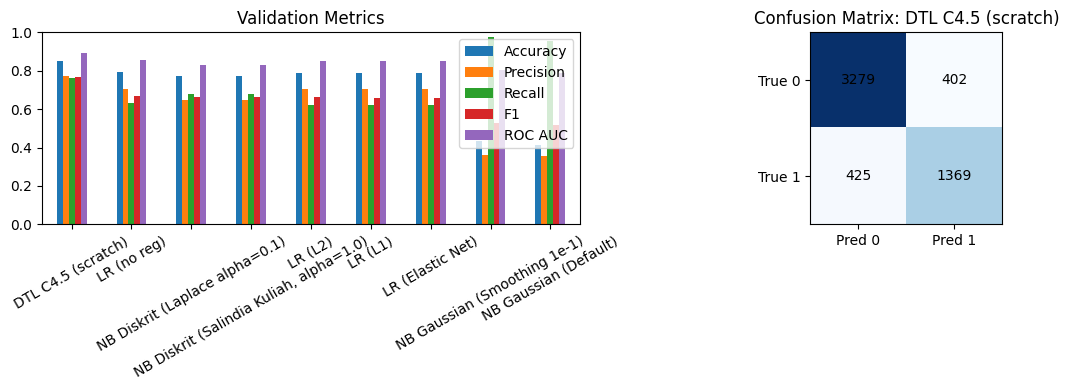

,Accuracy,Precision,Recall,F1,Macro F1,ROC AUC,Cost (2FP+FN)
LR (no reg),0.7945 ± 0.0060,0.7421 ± 0.0149,0.5712 ± 0.0071,0.6455 ± 0.0090,0.7504 ± 0.0067,0.8525 ± 0.0070,1182.8000 ± 46.0456
LR (L1),0.7928 ± 0.0067,0.7457 ± 0.0172,0.5582 ± 0.0156,0.6383 ± 0.0122,0.7466 ± 0.0081,0.8517 ± 0.0067,1178.6000 ± 50.8606
LR (L2),0.7932 ± 0.0053,0.7402 ± 0.0192,0.5688 ± 0.0140,0.6430 ± 0.0074,0.7487 ± 0.0052,0.8514 ± 0.0072,1191.0000 ± 53.6004
LR (Elastic Net),0.7933 ± 0.0061,0.7445 ± 0.0177,0.5621 ± 0.0061,0.6405 ± 0.0080,0.7477 ± 0.0063,0.8514 ± 0.0070,1180.2000 ± 51.9586


In [106]:
# Write your code here
def to_binary(y):
    return (np.asarray(y).ravel() > 0).astype(int)

def confusion(y_true, y_pred):
    y_true, y_pred = to_binary(y_true), to_binary(y_pred)
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    return tp, tn, fp, fn

def roc_auc(y_true, scores):
    y_true = to_binary(y_true)
    ranks = pd.Series(np.asarray(scores, dtype=float)).rank().values
    n1, n0 = np.sum(y_true == 1), np.sum(y_true == 0)
    if n1 == 0 or n0 == 0:
        return np.nan
    return (np.sum(ranks[y_true == 1]) - n1 * (n1 + 1) / 2) / (n1 * n0)

def compute_metrics(y_true, y_pred, scores=None, fp_cost=2.0, fn_cost=1.0):
    tp, tn, fp, fn = confusion(y_true, y_pred)
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    precision0 = tn / (tn + fn) if tn + fn else 0.0
    recall0 = tn / (tn + fp) if tn + fp else 0.0
    f1_0 = 2 * precision0 * recall0 / (precision0 + recall0) if precision0 + recall0 else 0.0
    return {"Accuracy": (tp + tn) / (tp + tn + fp + fn), "Precision": precision, "Recall": recall, "F1": f1, "Macro F1": (f1 + f1_0) / 2, "ROC AUC": roc_auc(y_true, scores) if scores is not None else np.nan, "TP": tp, "TN": tn, "FP": fp, "FN": fn, "Cost (2FP+FN)": fp_cost * fp + fn_cost * fn}

def get_scores(model, X):
    if hasattr(model, "predict_probability"):
        return np.asarray(model.predict_probability(X))[:, 1]
    if hasattr(model, "predict_proba"):
        return np.asarray(model.predict_proba(X))[:, 1]
    if hasattr(model, "decision_function"):
        return np.asarray(model.decision_function(X))
    return None

def evaluate_models(models, X, y):
    rows = {name: compute_metrics(y, model.predict(X), get_scores(model, X)) for name, model in models.items()}
    return pd.DataFrame(rows).T.sort_values("F1", ascending=False)

trained_models = {}
trained_models.update(lr_models)
if 'nb_models' in globals():
    for k, v in nb_models.items():
        if 'PCA' not in k:  
            trained_models[k] = v

if 'dtl_models' in globals(): 
    trained_models.update(dtl_models)

eval_df = evaluate_models(trained_models, X_val, y_val)
display(eval_df.round(4))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
eval_df[["Accuracy", "Precision", "Recall", "F1", "ROC AUC"]].plot.bar(ax=axes[0], rot=30)
axes[0].set_title("Validation Metrics")
axes[0].set_ylim(0, 1)
best_name = eval_df.index[0]
tp, tn, fp, fn = confusion(y_val, trained_models[best_name].predict(X_val))
axes[1].imshow([[tn, fp], [fn, tp]], cmap="Blues")
for (i, j), v in np.ndenumerate(np.array([[tn, fp], [fn, tp]])):
    axes[1].text(j, i, v, ha="center", va="center")
axes[1].set_xticks([0, 1], ["Pred 0", "Pred 1"])
axes[1].set_yticks([0, 1], ["True 0", "True 1"])
axes[1].set_title(f"Confusion Matrix: {best_name}")
plt.tight_layout()
plt.savefig(CFG.OUTPUT_DIR / "model_evaluation.png")
plt.show()

def stratified_kfold_indices(y, k=5, seed=42):
    y = to_binary(y)
    rng = np.random.default_rng(seed)
    folds = [[] for _ in range(k)]
    for cls in (0, 1):
        idx = rng.permutation(np.where(y == cls)[0])
        for f, part in enumerate(np.array_split(idx, k)):
            folds[f].extend(part.tolist())
    return [np.array(sorted(f)) for f in folds]

def cross_validate(make_model, X, y, k=5, seed=42):
    X, y = np.asarray(X), to_binary(y)
    folds = stratified_kfold_indices(y, k, seed)
    rows = []
    for f in range(k):
        val_idx = folds[f]
        train_idx = np.concatenate([folds[g] for g in range(k) if g != f])
        model = make_model().fit(X[train_idx], y[train_idx])
        rows.append(compute_metrics(y[val_idx], model.predict(X[val_idx]), get_scores(model, X[val_idx])))
    df = pd.DataFrame(rows)
    return df.mean(), df.std()

def cross_validate_models(factories, X, y, k=5, seed=42):
    cols = ["Accuracy", "Precision", "Recall", "F1", "Macro F1", "ROC AUC", "Cost (2FP+FN)"]
    rows = {}
    for name, make_model in factories.items():
        mean, std = cross_validate(make_model, X, y, k, seed)
        rows[name] = {c: f"{mean[c]:.4f} ± {std[c]:.4f}" for c in cols}
    return pd.DataFrame(rows).T

lr_factories = {name: (lambda cfg=cfg: LogisticRegression(lr=0.01, n_iter=30, random_state=CFG.SEED, **cfg)) for name, cfg in lr_configs.items()}
cv_df = cross_validate_models(lr_factories, X_train, y_train, k=5, seed=CFG.SEED)
display(cv_df)

## Improvements (Optional)

This part covers hyperparameter tuning, cross-validation, and further visualization.

In [88]:
# Write your code here
cs_models = {"LR (L2)": lr_models["LR (L2)"], "LR (L2, weighted)": LogisticRegression(penalty="l2", lam=0.001, class_weight={0: 2.0, 1: 1.0}, random_state=CFG.SEED).fit(X_train, y_train)}
val_probability = lr_models["LR (L2)"].predict_probability(X_val)[:, 1]
thresholds = np.linspace(0.05, 0.95, 91)
costs = [compute_metrics(y_val, (val_probability >= t).astype(int))["Cost (2FP+FN)"] for t in thresholds]
best_threshold = thresholds[int(np.argmin(costs))]
print(f"Best threshold = {best_threshold:.2f}  (theoretical 2/3 = {2/3:.2f})")
rows = {name: compute_metrics(y_val, m.predict(X_val), get_scores(m, X_val)) for name, m in cs_models.items()}
rows[f"LR (L2, thr={best_threshold:.2f})"] = compute_metrics(y_val, lr_models["LR (L2)"].predict(X_val, threshold=best_threshold), val_probability)
display(pd.DataFrame(rows).T[["Accuracy", "Precision", "Recall", "F1", "FP", "FN", "Cost (2FP+FN)"]].round(4))

Best threshold = 0.76  (theoretical 2/3 = 0.67)


,Accuracy,Precision,Recall,F1,FP,FN,Cost (2FP+FN)
LR (L2),0.7903,0.7031,0.6232,0.6608,472.0,676.0,1620.0
"LR (L2, weighted)",0.7777,0.8223,0.4103,0.5474,159.0,1058.0,1376.0
"LR (L2, thr=0.76)",0.7651,0.8499,0.3439,0.4897,109.0,1177.0,1395.0


In [89]:
feature_idx = int(np.argmax(np.abs(lr_models["LR (L2)"].coef_)))
x1 = X_train[:, [feature_idx]]
viz_model = LogisticRegression(penalty=None, lr=0.01, n_iter=30, tol=0, record_history=True, random_state=CFG.SEED).fit(x1, y_train)
path = np.array(viz_model.theta_history)
t0 = np.linspace(path[:, 0].min() - 1.5, path[:, 0].max() + 1.5, 120)
t1 = np.linspace(path[:, 1].min() - 1.5, path[:, 1].max() + 1.5, 120)
T0, T1 = np.meshgrid(t0, t1)
Z = np.zeros_like(T0)
yv = to_binary(y_train)
for i in range(T0.shape[0]):
    P = np.clip(1 / (1 + np.exp(-(T0[i][:, None] + T1[i][:, None] * x1.ravel()[None, :]))), 1e-12, 1 - 1e-12)
    Z[i] = -np.mean(yv * np.log(P) + (1 - yv) * np.log(1 - P), axis=1)
fig, ax = plt.subplots(figsize=(7, 6))
cs = ax.contour(T0, T1, Z, levels=30, cmap="viridis")
ax.clabel(cs, inline=True, fontsize=7)
line, = ax.plot([], [], "r.-")
title = ax.set_title("")
ax.set_xlabel(r"$\theta_0$")
ax.set_ylabel(r"$\theta_1$")

def update(k):
    line.set_data(path[:k + 1, 0], path[:k + 1, 1])
    title.set_text(f"Epoch {k}  loss={viz_model.loss_history[k]:.4f}")
    return line, title

anim = FuncAnimation(fig, update, frames=len(path), interval=150, blit=True)
try:
    anim.save(CFG.OUTPUT_DIR / "lr_loss_contour.mp4", writer=FFMpegWriter(fps=8))
except Exception:
    anim.save(CFG.OUTPUT_DIR / "lr_loss_contour.gif", writer=PillowWriter(fps=8))
plt.close(fig)

---

# Comparison with scikit-learn <a name="8"></a>

---

This section compares each from-scratch model with its `scikit-learn` counterpart.

In [ ]:
# Write your code here
with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    n = X_train.shape[0]
    sk_lr_configs = {"LR (no reg)": dict(C=np.inf, l1_ratio=0.0), "LR (L1)": dict(C=1 / (n * 0.001), l1_ratio=1.0), "LR (L2)": dict(C=1 / (n * 0.001), l1_ratio=0.0), "LR (Elastic Net)": dict(C=1 / (n * 0.001), l1_ratio=0.5)}
    sk_lr_models = {name: SkLogisticRegression(solver="saga", max_iter=5000, random_state=CFG.SEED, **cfg).fit(X_train, y_train) for name, cfg in sk_lr_configs.items()}
rows = []
for name in lr_models:
    ours = compute_metrics(y_val, lr_models[name].predict(X_val), get_scores(lr_models[name], X_val))
    sk = compute_metrics(y_val, sk_lr_models[name].predict(X_val), get_scores(sk_lr_models[name], X_val))
    agree = np.mean(lr_models[name].predict(X_val) == sk_lr_models[name].predict(X_val))
    coef_diff = np.max(np.abs(lr_models[name].coef_ - sk_lr_models[name].coef_.ravel()))
    rows.append({"Model": name, "Scratch F1": ours["F1"], "Sklearn F1": sk["F1"], "Scratch Acc": ours["Accuracy"], "Sklearn Acc": sk["Accuracy"], "Prediction Agreement": agree, "Max |coef diff|": coef_diff})
lr_compare_df = pd.DataFrame(rows).set_index("Model")
display(lr_compare_df.round(4))

t0 = time.perf_counter()
nb_scratch = NaiveBayes(var_smoothing=1e-9).fit(X_train, y_train)
t_fit_scratch = time.perf_counter() - t0

t0 = time.perf_counter()
preds_scratch = nb_scratch.predict(X_val)
t_infer_scratch = time.perf_counter() - t0

t0 = time.perf_counter()
nb_sk = SkGaussianNB(var_smoothing=1e-9).fit(X_train, y_train)
t_fit_sk = time.perf_counter() - t0

t0 = time.perf_counter()
preds_sk = nb_sk.predict(X_val)
t_infer_sk = time.perf_counter() - t0

nb_agree = np.mean(preds_scratch == preds_sk)
max_p_diff = np.max(np.abs(nb_scratch.predict_proba(X_val) - nb_sk.predict_proba(X_val)))

m_scratch = compute_metrics(y_val, preds_scratch, get_scores(nb_scratch, X_val))
m_sk = compute_metrics(y_val, preds_sk, get_scores(nb_sk, X_val))

nb_compare_df = pd.DataFrame([{
    'Model': 'Gaussian Naive Bayes',
    'Scratch F1': m_scratch['F1'],
    'Sklearn F1': m_sk['F1'],
    'Scratch Macro F1': m_scratch['Macro F1'],
    'Sklearn Macro F1': m_sk['Macro F1'],
    'Scratch Acc': m_scratch['Accuracy'],
    'Sklearn Acc': m_sk['Accuracy'],
    'Prediction Agreement': nb_agree,
    'Max |proba diff|': max_p_diff,
    'Scratch Fit Time (s)': t_fit_scratch,
    'Sklearn Fit Time (s)': t_fit_sk,
}]).set_index('Model')
print('\nPerbandingan Naive Bayes (From Scratch vs scikit-learn):')
display(nb_compare_df.round(6))

import time

t0 = time.perf_counter()
nb_scratch = NaiveBayes(method='gaussian', var_smoothing=1e-9).fit(X_train, y_train)
t_fit_scratch = time.perf_counter() - t0

t0 = time.perf_counter()
preds_scratch = nb_scratch.predict(X_val)
t_infer_scratch = time.perf_counter() - t0

t0 = time.perf_counter()
nb_sk = SkGaussianNB(var_smoothing=1e-9).fit(X_train, y_train)
t_fit_sk = time.perf_counter() - t0

t0 = time.perf_counter()
preds_sk = nb_sk.predict(X_val)
t_infer_sk = time.perf_counter() - t0

nb_agree = np.mean(preds_scratch == preds_sk)
max_p_diff = np.max(np.abs(nb_scratch.predict_proba(X_val) - nb_sk.predict_proba(X_val)))

m_scratch = compute_metrics(y_val, preds_scratch, get_scores(nb_scratch, X_val))
m_sk = compute_metrics(y_val, preds_sk, get_scores(nb_sk, X_val))

nb_compare_df = pd.DataFrame([{
    'Model': 'Gaussian Naive Bayes',
    'Scratch F1': m_scratch['F1'],
    'Sklearn F1': m_sk['F1'],
    'Scratch Macro F1': m_scratch['Macro F1'],
    'Sklearn Macro F1': m_sk['Macro F1'],
    'Scratch Acc': m_scratch['Accuracy'],
    'Sklearn Acc': m_sk['Accuracy'],
    'Prediction Agreement': nb_agree,
    'Max |proba diff|': max_p_diff,
    'Scratch Fit Time (s)': t_fit_scratch,
    'Sklearn Fit Time (s)': t_fit_sk,
}]).set_index('Model')
print('\nPerbandingan Naive Bayes (From Scratch vs scikit-learn):')
display(nb_compare_df.round(6))


# Evaluasi dan Perbandingan Algoritma Decision Tree Learning
mulai = time.perf_counter()
sc_pred = dtl_model.predict(X_val)
sc_pred_time = time.perf_counter() - mulai

hasil_komparasi = {}
hasil_komparasi["DTL C4.5 (scratch)"] = {
    **compute_metrics(y_val, sc_pred, get_scores(dtl_model, X_val)),
    "Fit Time (s)": float(best_params["fit_time_s"]),
    "Predict Time (s)": sc_pred_time
}

sk_models = {}
for alpha in [0.0, 0.0002, 0.001]:
    mulai = time.perf_counter()
    sk_dt = DecisionTreeClassifier(
        criterion="entropy",
        max_depth=best_depth,
        min_samples_split=10,
        min_samples_leaf=best_leaf,
        ccp_alpha=alpha,
        random_state=CFG.SEED
    )
    sk_dt.fit(X_train, y_train)
    fit_time = time.perf_counter() - mulai

    mulai = time.perf_counter()
    sk_pred = sk_dt.predict(X_val)
    pred_time = time.perf_counter() - mulai

    nama_model = f"sklearn (entropy, ccp_alpha={alpha})"
    sk_models[nama_model] = sk_dt
    hasil_komparasi[nama_model] = {
        **compute_metrics(y_val, sk_pred, get_scores(sk_dt, X_val)),
        "Fit Time (s)": fit_time,
        "Predict Time (s)": pred_time,
        "Prediction Agreement": float(np.mean(sk_pred == sc_pred))
    }

dtl_compare_df = pd.DataFrame(hasil_komparasi).T
dtl_compare_df.index.name = "Model"
nama_kolom = ["Accuracy", "F1", "ROC AUC", "FP", "FN", "Fit Time (s)", "Predict Time (s)", "Prediction Agreement"]
print("\nPerbandingan Decision Tree Learning (From Scratch vs scikit-learn):")
display(dtl_compare_df[nama_kolom].round(4))

,Scratch F1,Sklearn F1,Scratch Acc,Sklearn Acc,Prediction Agreement,Max |coef diff|
Model,,,,,,
LR (no reg),0.6671,0.6677,0.7934,0.8022,0.9518,2.5019
LR (L1),0.6604,0.6590,0.7901,0.7985,0.9514,0.2035
LR (L2),0.6608,0.6564,0.7903,0.7969,0.9485,0.2234
LR (Elastic Net),0.6602,0.6576,0.7901,0.7976,0.9501,0.1910



Perbandingan Naive Bayes (From Scratch vs scikit-learn):


,Scratch F1,Sklearn F1,Scratch Macro F1,Sklearn Macro F1,Scratch Acc,Sklearn Acc,Prediction Agreement,Max |proba diff|,Scratch Fit Time (s),Sklearn Fit Time (s)
Model,,,,,,,,,,
Gaussian Naive Bayes,0.661765,0.516479,0.745557,0.385069,0.773151,0.413151,0.445662,0.999839,0.029894,0.018688



Perbandingan Naive Bayes (From Scratch vs scikit-learn):


,Scratch F1,Sklearn F1,Scratch Macro F1,Sklearn Macro F1,Scratch Acc,Sklearn Acc,Prediction Agreement,Max |proba diff|,Scratch Fit Time (s),Sklearn Fit Time (s)
Model,,,,,,,,,,
Gaussian Naive Bayes,0.516479,0.516479,0.385069,0.385069,0.413151,0.413151,1.0,0.0,0.016668,0.013658



Perbandingan Decision Tree Learning (From Scratch vs scikit-learn):


,Accuracy,F1,ROC AUC,FP,FN,Fit Time (s),Predict Time (s),Prediction Agreement
Model,,,,,,,,
DTL C4.5 (scratch),0.8489,0.7680,0.8914,402.0,425.0,24.8525,0.2849,NaN
"sklearn (entropy, ccp_alpha=0.0)",0.8489,0.7687,0.8871,407.0,420.0,0.1525,0.0025,0.8926
"sklearn (entropy, ccp_alpha=0.0002)",0.8590,0.7787,0.9102,336.0,436.0,0.1374,0.0020,0.9096
"sklearn (entropy, ccp_alpha=0.001)",0.8473,0.7546,0.9040,327.0,509.0,0.1738,0.0010,0.9319


### Insight Comparison From Scratch Models with Scikit-Learn

#### 1.
#### 2. Decision Tree Learning (DTL)
Ketika model DTL yang dibuat from scratch menggunakan algoritma C4.5 dibandingkan dengan model DTL yang ada pada library Scikit-learn, terlihat bahwa terdapat beberapa variasi kombinasi hasil ketika dibandingkan dengan model sklearn yang menggunakan beberapa variasi ccp alpha, sebesar 0, 0.0002, dan 0.001. 

Pada sklearn yang tidak melakukan post pruning (ccp_alpha = 0.0), terlihat bahwa akurasi prediksi model memiliki nilai yang sama dengan model from scratch. Hal ini menunjukkan bahwa model from scratch yang dibuat sudah cukup baik dan tepat dan bebas dari bug, namun prediksi tetap tidak identik (89%). Dari sisi kemampuan pemisahan probabilitas kelas, skor ROC AUC model from scratch (0,8914) bahkan sedikit mengungguli Scikit-learn tanpa pruning (0,8871), namun kembali dilampaui ketika Scikit-learn menerapkan post-pruning ccp_alpha = 0.0002 (0,9102). Adapun untuk skor F1 model scratch dibandingkan dengan model sklearn, terlihat memiliki selisih sebesar 0.0007 dengan waktu modeling dan prediksi sklearn yang jauh lebih cepat dari model from scratch, sekitar lebih kurang 100 kali lebih cepat (detail skala percepatannya tidak dituliskan karena berpotensi akan berbeda-beda setiap run ulang). Selain itu, semakin besar nilai ccp_alpha, model cenderung lebih konservatif dalam memprediksi pembatalan sehingga jumlah False Positive menurun (dari 407 menjadi 327), namun diiringi lonjakan False Negative (dari 420 menjadi 509) yang menyebabkan penurunan nilai F1.

Begitu juga dengan model sklearn yang menggunakan post pruning, terlihat bahwa akurasi prediksi yang menggunakan ccp_alpha sebesar 0.0002 merupakan yang paling baik. Sedangkan model yang menggunakan ccp_alpha 0.001 memiliki akurasi yang 0.0016 lebih buruk dibandingkan model from scratch. Hal ini menunjukkan bahwa pruning pohon yang terlalu besar mengakibatkan model menjadi underfit. Namun model sklearn dengan ccp_alpha sebesar 0.001 memiliki kemiripan hasil prediksi yang paling dekat dengan model from scratch ini.

Berdasarkan hasil perbandingan model ini, dapat disimpulkan bahwa model from scratch sudah cukup baik untuk melakukan prediksi namun model sklearn jauh lebih baik dari segi waktu komputasi saat modeling dan prediksinya. Hal ini dapat disebabkan karena pada model sklearn, digunakan semua information gainnya, dilengkapi post pruning, serta tentunya sudah dioptimasi agar bisa melakukan komputasi yang lebih cepat. Sedangkan model DTL from scratch menggunakan algoritma C4.5 yang hanya dibatasi sampai maksimum threshold sebesar 32 kuantil pada fitur numeriknya agar waktu modeling tidak terlalu lama karena harus melakukan pengujian semua titik yang jumlahnya sangat banyak.

#### 3.
#### 4.
#### 5.

---

# Saving and Loading Models <a name="9"></a>

---

<!-- artifacts: <model>_v3.pkl -->

This section stores the trained models and restores them for prediction.

In [91]:
# Write your code here
for name, model in lr_models.items():
    path = CFG.OUTPUT_DIR / f"{name.replace(' ', '_').replace('(', '').replace(')', '').lower()}.pkl"
    model.save(path)
    loaded = LogisticRegression.load(path)
    print(f"{path.name}: identical predictions = {np.array_equal(model.predict(X_val), loaded.predict(X_val))}")

# Save and load Naive Bayes models
if 'nb_models' in globals():
    for name, model in nb_models.items():
        if 'PCA' in name:
            continue
        clean = name.replace(' ', '_').replace('(', '').replace(')', '').replace('-', '_').lower()
        path = CFG.OUTPUT_DIR / f'{clean}.json'
        model.save(path)
        loaded = NaiveBayes.load(path)
        print(f'{path.name}: identical predictions = {np.array_equal(model.predict(X_val), loaded.predict(X_val))}')

# Save dan Load Decision Tree Learning
dtl_path = CFG.OUTPUT_DIR / 'dtl_c45.pkl'
dtl_model.save(dtl_path)
dtl_loaded = DecisionTree.load(dtl_path)
print(f'{dtl_path.name}: identical predictions = '
      f'{np.array_equal(dtl_model.predict(X_val), dtl_loaded.predict(X_val))}')

lr_no_reg.pkl: identical predictions = True
lr_l1.pkl: identical predictions = True
lr_l2.pkl: identical predictions = True
lr_elastic_net.pkl: identical predictions = True
nb_diskrit_salindia_kuliah,_alpha=1.0.json: identical predictions = True
nb_diskrit_laplace_alpha=0.1.json: identical predictions = True
nb_gaussian_default.json: identical predictions = True
nb_gaussian_smoothing_1e_1.json: identical predictions = True
dtl_c45.pkl: identical predictions = True


---

# Kaggle Submission <a name="10"></a>

---

The final pipeline and model are fitted on the original training set, and the test set is only transformed. The submission file contains the `id` and `is_canceled` columns.

In [ ]:
# Final Training
final_train_df = remove_duplicates(train_df, id_col='id').reset_index(drop=True)
y_full = final_train_df[TARGET].to_numpy()

final_prep = Preprocessor(**DEFAULT_PREP_PARAMS).fit(final_train_df)
X_full = final_prep.transform(final_train_df)
X_test_final = final_prep.transform(test_df)

assert X_full.shape[0] == len(y_full)
assert X_full.shape[1] == X_test_final.shape[1] == X_train.shape[1], 'jumlah fitur harus sama'
assert not np.isnan(X_test_final).any(), 'X_test_final tidak boleh berisi NaN'
print('X_full:', X_full.shape, '\nX_test_final:', X_test_final.shape)

# Daftar model final
final_models = {
    'dtl': DecisionTree(max_depth=best_depth, min_samples_split=10,
                        min_samples_leaf=best_leaf, categorical_idx=[],
                        max_thresholds=32).fit(X_full, y_full),
    # 'logreg': 
    # 'nb': 
    # 'knn' : 
    # 'nvm' :  
}
SAVE_EXT = {'dtl': '.pkl', 'logreg': '.pkl', 'nb': '.json'}  # ekstensi save/load per model (tambahkan yang nvm dan knn juga sesuai jenis file nya)
MAIN_MODEL = 'dtl'   # model yang menjadi output/submission.csv (yang diunggah ke Kaggle, sesuaikan)

def to_label(p):
    return (np.asarray(p).ravel() > 0).astype(int)   # aman untuk label 0/1 maupun -1/+1

submissions = {}
for name, model in final_models.items():
    # Save/load: prediksi sebelum dan sesudah harus identik
    path = CFG.OUTPUT_DIR / f'final_{name}{SAVE_EXT.get(name, ".pkl")}'
    model.save(path)
    loaded = type(model).load(path)
    pred = to_label(model.predict(X_test_final))
    assert np.array_equal(pred, to_label(loaded.predict(X_test_final))), f'save/load berbeda: {name}'

    sub_file = CFG.OUTPUT_DIR / f'submission_{name}.csv'
    pd.DataFrame({'id': test_df['id'].astype(str), 'is_canceled': pred}).to_csv(sub_file, index=False)
    submissions[name] = sub_file
    print(f"[{name}] {pred.shape[0]} baris | distribusi {pd.Series(pred).value_counts(normalize=True).round(3).to_dict()}"
          f" | sha256 {hashlib.sha256(sub_file.read_bytes()).hexdigest()[:16]}")

# Submisi utama Kaggle : salinan dari model terpilih
sub_path = CFG.OUTPUT_DIR / 'submission.csv'
sub_path.write_bytes(submissions[MAIN_MODEL].read_bytes())
print(f'\nsubmission.csv <- {MAIN_MODEL} | sha256: {hashlib.sha256(sub_path.read_bytes()).hexdigest()}')

X_full: (27309, 37) 
X_test_final: (6844, 37)
[dtl] 6844 baris | distribusi {0: 0.692, 1: 0.308} | sha256 ee1ec3e91b493200

submission.csv <- dtl | sha256: ee1ec3e91b493200cc3f5b11315fc744997cee2c7eaca4491807464829295dbf


---

# Error Analysis <a name="11"></a>

---

The analysis supports each step taken in this notebook.